# Dataset Insights (Multi-Solver)
This notebook summarizes a generated dataset of elevation-map paths and computes additional insights for multiple pathfinding solvers.

For each configured solver (e.g., `astar_elevation`, `astar_energy`, `astar_slope`), we analyze:
- path crossing heatmap (free and obstacles paths)
- elevation distributions
- path length distribution per solver
- normalized relative elevation profile
- normalized Hausdorff distances per solver
- identical path count per solver
- cost difference per solver
- pathfinding timing per solver

## 1. Setup and Configuration
Import libraries, configure solver, and load calibration and dataset summary files.


In [20]:
import json
import sys
import os
import math
import multiprocessing as mp
from pathlib import Path
from collections import Counter
from concurrent.futures import ProcessPoolExecutor

import matplotlib.pyplot as plt
from matplotlib import cm
import numpy as np
import pandas as pd
import yaml
from tqdm import tqdm
from loguru import logger as loguru_logger

# Define ROOT path first (notebook is in notebooks/)
ROOT = Path("..").resolve()

try:
    from passage.generate import _resolve_solver_config
except Exception:
    # If import fails (e.g., running in notebook without package installed),
    # temporarily prepend local `src` to sys.path and retry.
    sys.path.insert(0, str(ROOT / "src"))
    from passage.generate import _resolve_solver_config

# Configure loguru for info level
loguru_logger.remove()
loguru_logger.add(sys.stderr, level="INFO");

In [21]:
# Parameters (papermill)
RESOLUTION = 512
SPLITS = ["train", "calibration", "validation", "test"]
MAX_WORKERS = 32
DATASET_DIRPATH = "../outputs/dataset"
CONFIG_FILEPATH = "../config/config.yaml"
CALIBRATE_FILEPATH = "../outputs/calibrate/calibrate.json"

In [22]:
# Paths
CONFIG_FILEPATH = Path(CONFIG_FILEPATH)
CALIBRATE_FILEPATH = Path(CALIBRATE_FILEPATH)
DATASET_DIRPATH = Path(DATASET_DIRPATH)
RESOLUTION_DIRPATH = DATASET_DIRPATH / str(RESOLUTION)

# Solver config and solver names
with open(CONFIG_FILEPATH) as f:
    _config = yaml.safe_load(f) or {}

# Get list of solver configurations from config
_solvers_cfg = _config.get("solvers", [])
if isinstance(_solvers_cfg, list):
    SOLVER_NAMES = [s.get("name") for s in _solvers_cfg if isinstance(s, dict) and s.get("name")]
else:
    SOLVER_NAMES = []

# Default to first solver's config if available (backward compatibility)
if _solvers_cfg:
    _solver_cfg = _solvers_cfg[0]
    SOLVER_CONFIG = _resolve_solver_config(_solver_cfg)
else:
    SOLVER_CONFIG = {}

# Calibration
with open(CALIBRATE_FILEPATH) as f:
    calibration = json.load(f)

global_min = float(calibration["global_min"])
global_max = float(calibration["global_max"])

print(f"Global elevation range: [{global_min:.1f}, {global_max:.1f}]")
print(f"Configured solvers: {SOLVER_NAMES}")

Global elevation range: [-430.0, 8767.0]
Configured solvers: ['astar_elevation', 'astar_energy', 'astar_slope']


## 2. Dataset Generation
For each dataset sample, we load the stored paths from CSV files for each solver (free and obstacles).
Metadata contains per-solver path statistics (length, cost, timing) while actual pixel coordinates are stored in:
- `paths/<solver_name>/free/*.csv` - paths computed without obstacles
- `paths/<solver_name>/obstacles/*.csv` - paths computed with obstacles

Metrics are computed for each sample using multiprocessing to speed up processing across CPU cores.

### Metric computations and explanations

For each solver configured in `config.yaml`, we compute metrics on both free (without obstacles) and obstacles (with obstacles) paths loaded from CSV files.

- **Path Occurrence Heatmap**: for every sample and solver, we increment a per-pixel counter for each pixel that belongs to the path. Results shown separately for each solver and path type (free/obstacles).

- **Covered Tiles Visualization**: we count how often each source tile appears in `tiles_used` and visualize coverage in a lat/lon scatter plot, colored by usage frequency.

- **Start Point Elevation Distribution**: histogram of the elevation at the first pixel of each stored path. This helps understand where paths begin (e.g., high vs low terrain).

- **All Path Points Elevation Distribution**: histogram aggregating elevation values for every path pixel across all samples.

- **Path Length Distribution**: histogram of path lengths measured as number of pixels in the stored path.

- **Normalized Relative Path Elevation Profile**: for each stored path we subtract the start elevation (relative elevation) and resample the sequence to 100 uniformly spaced points in the normalized path domain [0, 1]. We then compute the mean and standard deviation across samples to show a typical elevation trend along a path.

- **Normalized Hausdorff Distance**: we compute the Hausdorff distance $H(P,Q)$ between two paths and normalize by the straight-line (marker) distance $D$ between start and end: normalized = $H(P,Q) / D$. Computed per-solver:
  - **Free vs Straight**: $P$ = free path, $Q$ = straight-line markers path. Measures terrain-induced deviation from straight.
  - **Obstacles vs Free**: $P$ = obstacles path, $Q$ = free path. Measures deviation specifically introduced by obstacles.

- **Identical Path Count**: per-solver count of samples where the obstacles path exactly equals the free path (exact pixel list equality).

- **Per-Solver Comparison**: additional sections show path lengths, Hausdorff distances, cost differences, and timing breakdowns across all configured solvers.

In [ ]:
import csv
import zstandard as zstd

splits = {}

# Use first solver as reference for global elevation statistics
# (elevations are the same across solvers since they traverse same terrain)
start_elevations = []
all_elevations = []
path_lengths = []
normalized_profiles = []
hausdorff_clean_straight = []
hausdorff_obs_clean = []
area_ratios = []
cost_diff_percents = []

# Per-solver metrics with elevation profiles
solver_metrics = {
    name: {
        "path_lengths_free": [],
        "path_lengths_obstacles": [],
        "hausdorff_free_straight": [],
        "hausdorff_obs_free": [],
        "cost_diff_percents": [],
        "identical_paths_count": 0,
        "profiles_free": [],
        "profiles_obstacles": [],
    }
    for name in SOLVER_NAMES
}

# Timing buckets
graph_prebuild_seconds = []
obstacle_generation_seconds = []
cost_compute_seconds = []
tile_loading_seconds = []
marker_search_seconds = []
tensor_save_seconds = []
metadata_write_seconds = []
image_conversion_seconds = []
image_write_seconds = []

# Per-solver timing
solver_timing = {name: {"pathfind_free": [], "pathfind_obstacles": [], "cost_compute": []} for name in SOLVER_NAMES}

# Counters
samples_processed = 0
identical_paths_count = 0  # All solvers have identical free/obstacles paths

TIMING_KEYS = [
    "graph_prebuild_seconds",
    "obstacle_generation_seconds",
    "cost_compute_seconds",
    "tile_loading_seconds",
    "marker_search_seconds",
    "tensor_save_seconds",
    "metadata_write_seconds",
    "image_conversion_seconds",
    "image_write_seconds",
]

num_workers = MAX_WORKERS or os.cpu_count() or 1
try:
    num_workers = int(num_workers)
    if num_workers <= 0:
        num_workers = 1
except Exception:
    num_workers = 1
print(f"Using {num_workers} worker(s) for metadata processing")
print(f"Processing paths for solvers: {SOLVER_NAMES}")
ctx = mp.get_context("fork")


def describe_stats(values, label):
    if not values:
        print(f"{label}: no data")
        return
    series = pd.Series(values, dtype="float64")
    desc = series.describe(percentiles=[0.25, 0.5, 0.75])
    std = desc.get("std", float("nan"))
    std_val = 0.0 if pd.isna(std) else std
    print(
        f"{label}: count={int(desc['count'])}, mean={desc['mean']:.2f}, std={std_val:.2f}, "
        f"min={desc['min']:.2f}, p25={desc['25%']:.2f}, median={desc['50%']:.2f}, "
        f"p75={desc['75%']:.2f}, max={desc['max']:.2f}"
    )


def _load_path_from_csv(csv_path: Path):
    """Load path coordinates from CSV file."""
    coords = []
    if not csv_path.exists():
        return coords
    try:
        with open(csv_path, "r", newline="") as f:
            reader = csv.reader(f)
            for row in reader:
                if len(row) >= 2:
                    coords.append((int(row[0]), int(row[1])))
    except Exception:
        pass
    return coords


def _load_tensor(tensor_path: Path, resolution: int):
    """Load tensor from compressed .npy.zst file."""
    if not tensor_path.exists():
        return None
    try:
        d = zstd.ZstdDecompressor()
        blob = tensor_path.read_bytes()
        b = d.decompress(blob)
        return np.frombuffer(b, dtype=np.float32).reshape((resolution, resolution, 3))
    except Exception:
        return None


def _get_elevations_along_path(tensor, path, global_min, global_max):
    """Extract elevation values along a path from tensor."""
    if tensor is None or not path:
        return []
    elevations = []
    for i, j in path:
        if 0 <= i < tensor.shape[0] and 0 <= j < tensor.shape[1]:
            normalized = tensor[i, j, 0]
            elevation = normalized * (global_max - global_min) + global_min
            elevations.append(float(elevation))
    return elevations


def resample_profile(elevations, target_len=100):
    if not elevations:
        return None
    rel = np.array(elevations, dtype=float) - float(elevations[0])
    if len(rel) == 1:
        return rel.tolist() * target_len
    x_old = np.linspace(0.0, 1.0, num=len(rel))
    x_new = np.linspace(0.0, 1.0, num=target_len)
    return np.interp(x_new, x_old, rel).tolist()


def make_straight_path(start_point, end_point, n_points):
    if not start_point or not end_point or n_points <= 1:
        return []
    start = np.array([start_point.get("i", 0), start_point.get("j", 0)], dtype=float)
    end = np.array([end_point.get("i", 0), end_point.get("j", 0)], dtype=float)
    t = np.linspace(0.0, 1.0, num=n_points)
    pts = start[None, :] + (end - start)[None, :] * t[:, None]
    return [(int(round(p[0])), int(round(p[1]))) for p in pts]


def hausdorff_distance(path_a, path_b):
    if not path_a or not path_b:
        return None
    a = np.array(path_a, dtype=float)
    b = np.array(path_b, dtype=float)
    dists = np.sqrt(((a[:, None, :] - b[None, :, :]) ** 2).sum(axis=2))
    return float(max(dists.min(axis=1).max(), dists.min(axis=0).max()))


def relative_area_between_paths(path_a, path_b, marker_dist, samples=100):
    if marker_dist is None or marker_dist <= 0 or not path_a or not path_b:
        return None

    def _resample(path):
        pts = np.array(path, dtype=float)
        if len(pts) == 1:
            return np.repeat(pts, samples, axis=0)
        x_old = np.linspace(0.0, 1.0, num=len(pts))
        x_new = np.linspace(0.0, 1.0, num=samples)
        i_vals = np.interp(x_new, x_old, pts[:, 0])
        j_vals = np.interp(x_new, x_old, pts[:, 1])
        return np.stack([i_vals, j_vals], axis=1)

    a_rs, b_rs = _resample(path_a), _resample(path_b)
    dists = np.linalg.norm(a_rs - b_rs, axis=1)
    area = np.trapezoid(dists, x=np.linspace(0.0, 1.0, num=samples))
    return float(area / (marker_dist**2))


def _process_metadata(args):
    """Process a single metadata file with its associated path CSV files and tensor."""
    md_path, split_dirpath, solver_names, resolution, g_min, g_max = args
    try:
        with open(md_path) as f:
            md = yaml.safe_load(f) or {}
    except Exception:
        return None

    # Get sample index and location from metadata path
    sample_id = md_path.stem  # e.g., "0000000000"
    # Structure: metadata/<lat>/<lon>/<index>.yaml
    lon_dir = md_path.parent.name
    lat_dir = md_path.parent.parent.name

    tile_counts = Counter()
    for tile in md.get("tile", {}).get("overlapping", []):
        try:
            lat = int(tile.get("lat"))
            lon = int(tile.get("lon"))
            tile_counts[(lat, lon)] += 1
        except Exception:
            continue

    # Load tensor for elevation profiles
    tensor_path = split_dirpath / "tensors" / lat_dir / lon_dir / f"{sample_id}.npy.zst"
    tensor = _load_tensor(tensor_path, resolution)

    # Load paths for each solver from CSV files
    solver_paths = {}
    for solver_name in solver_names:
        free_csv = split_dirpath / "paths" / solver_name / "free" / lat_dir / lon_dir / f"{sample_id}.csv"
        obs_csv = split_dirpath / "paths" / solver_name / "obstacles" / lat_dir / lon_dir / f"{sample_id}.csv"
        solver_paths[solver_name] = {
            "free": _load_path_from_csv(free_csv),
            "obstacles": _load_path_from_csv(obs_csv),
        }

    # Build grid counts for each solver and path type
    grids = {}
    for solver_name in solver_names:
        grids[f"{solver_name}_free"] = Counter(solver_paths[solver_name]["free"])
        grids[f"{solver_name}_obstacles"] = Counter(solver_paths[solver_name]["obstacles"])

    # Check identical paths per solver
    identical_per_solver = {}
    for solver_name in solver_names:
        free_path = solver_paths[solver_name]["free"]
        obs_path = solver_paths[solver_name]["obstacles"]
        identical_per_solver[solver_name] = 1 if free_path and obs_path and free_path == obs_path else 0

    # All solvers have identical paths?
    all_identical = 1 if all(v == 1 for v in identical_per_solver.values()) else 0

    # Use first solver's obstacles path for global elevation statistics
    ref_solver = solver_names[0] if solver_names else None
    # ref_obs_path = solver_paths.get(ref_solver, {}).get("obstacles", []) if ref_solver else []

    # Extract elevation data from tensor for each solver path
    start_vals = []
    all_vals = []
    profile = None

    # Compute elevation profiles for all solvers and both path types
    solver_profiles = {}
    for solver_name in solver_names:
        free_path = solver_paths[solver_name]["free"]
        obs_path = solver_paths[solver_name]["obstacles"]

        free_elevs = _get_elevations_along_path(tensor, free_path, g_min, g_max)
        obs_elevs = _get_elevations_along_path(tensor, obs_path, g_min, g_max)

        solver_profiles[solver_name] = {
            "profile_free": resample_profile(free_elevs),
            "profile_obstacles": resample_profile(obs_elevs),
        }

        # Populate global stats from reference solver's obstacles path
        if solver_name == ref_solver and obs_elevs:
            start_vals.append(float(obs_elevs[0]))
            all_vals.extend(obs_elevs)
            profile = resample_profile(obs_elevs)

    # Get marker info for Hausdorff calculations
    marker_start = md.get("markers", {}).get("start_point", {}) or {}
    marker_end = md.get("markers", {}).get("end_point", {}) or {}
    try:
        marker_dist = math.dist(
            (float(marker_start.get("i")), float(marker_start.get("j"))),
            (float(marker_end.get("i")), float(marker_end.get("j"))),
        )
    except Exception:
        marker_dist = None

    # Per-solver Hausdorff and metrics
    solver_metrics_result = {}
    for solver_name in solver_names:
        free_path = solver_paths[solver_name]["free"]
        obs_path = solver_paths[solver_name]["obstacles"]

        h_free_norm = None
        h_obs_norm = None
        if marker_dist and marker_dist > 0:
            straight_path = make_straight_path(marker_start, marker_end, max(len(free_path), 2))
            h_free = hausdorff_distance(free_path, straight_path)
            if h_free is not None:
                h_free_norm = float(h_free / marker_dist)
            h_obs = hausdorff_distance(obs_path, free_path)
            if h_obs is not None:
                h_obs_norm = float(h_obs / marker_dist)

        # Get cost diff from metadata
        paths_md = md.get("paths", {}).get(solver_name, {})
        cost_percent = paths_md.get("obstacles", {}).get("cost_diff_percent")
        cost_percent = float(cost_percent) if cost_percent is not None else None

        solver_metrics_result[solver_name] = {
            "path_length_free": len(free_path),
            "path_length_obstacles": len(obs_path),
            "hausdorff_free": h_free_norm,
            "hausdorff_obs": h_obs_norm,
            "cost_percent": cost_percent,
            "identical": identical_per_solver[solver_name],
            "profile_free": solver_profiles[solver_name]["profile_free"],
            "profile_obstacles": solver_profiles[solver_name]["profile_obstacles"],
        }

    # Use first solver for global metrics (backward compatibility)
    if ref_solver and ref_solver in solver_metrics_result:
        ref_metrics = solver_metrics_result[ref_solver]
        h_clean_norm = ref_metrics["hausdorff_free"]
        h_obs_norm = ref_metrics["hausdorff_obs"]
        cost_percent_ref = ref_metrics["cost_percent"]
        path_length = ref_metrics["path_length_obstacles"]
    else:
        h_clean_norm = None
        h_obs_norm = None
        cost_percent_ref = None
        path_length = 0

    # Global timing from metadata
    timing_md = md.get("timing", {}) or {}
    timing_vals = {k: timing_md.get(k) for k in TIMING_KEYS}

    # Per-solver timing
    solver_timing_result = {}
    for solver_name in solver_names:
        paths_md = md.get("paths", {}).get(solver_name, {})
        timing_per = paths_md.get("timing", {})
        solver_timing_result[solver_name] = {
            "pathfind_free": timing_per.get("pathfind_free_seconds"),
            "pathfind_obstacles": timing_per.get("pathfind_obstacles_seconds"),
            "cost_compute": timing_per.get("cost_compute_seconds"),
        }

    return {
        "tile_overlapping": tile_counts,
        "grids": grids,
        "identical_paths": all_identical,
        "identical_per_solver": identical_per_solver,
        "samples_processed": 1,
        "start_elevations": start_vals,
        "all_elevations": all_vals,
        "profile": profile,
        "path_length": path_length,
        "hausdorff_clean": h_clean_norm,
        "hausdorff_obs": h_obs_norm,
        "cost_percent": cost_percent_ref,
        "timing": timing_vals,
        "solver_metrics": solver_metrics_result,
        "solver_timing": solver_timing_result,
    }


for split in SPLITS:
    # Dataset paths and summary (derived from parameters)
    split_dirpath = RESOLUTION_DIRPATH / split
    metadata_dirpath = split_dirpath / "metadata"
    tensors_dirpath = split_dirpath / "tensors"
    images_dirpath = split_dirpath / "images"

    metadata_filepaths = sorted(metadata_dirpath.rglob("**/*.yaml"))

    tile_overlapping = Counter()

    # Initialize grids for each solver and path type
    grids_per_solver = {}
    for solver_name in SOLVER_NAMES:
        grids_per_solver[f"{solver_name}_free"] = np.zeros((RESOLUTION, RESOLUTION), dtype=np.int32)
        grids_per_solver[f"{solver_name}_obstacles"] = np.zeros((RESOLUTION, RESOLUTION), dtype=np.int32)

    if metadata_filepaths:
        # Prepare args for parallel processing (include global_min/max for elevation extraction)
        process_args = [
            (fp, split_dirpath, SOLVER_NAMES, RESOLUTION, global_min, global_max) for fp in metadata_filepaths
        ]

        effective_workers = min(num_workers, len(metadata_filepaths))
        with ProcessPoolExecutor(max_workers=effective_workers, mp_context=ctx) as executor:
            for res in tqdm(
                executor.map(_process_metadata, process_args),
                total=len(metadata_filepaths),
                desc=f"Processing {split} metadata (parallel)",
            ):
                if not res:
                    continue

                tile_overlapping.update(res["tile_overlapping"])

                # Update grids for each solver
                for grid_key, counts in res["grids"].items():
                    for (i, j), cnt in counts.items():
                        if 0 <= i < RESOLUTION and 0 <= j < RESOLUTION:
                            grids_per_solver[grid_key][i, j] += cnt

                identical_paths_count += res["identical_paths"]
                samples_processed += res["samples_processed"]

                start_elevations.extend(res["start_elevations"])
                all_elevations.extend(res["all_elevations"])

                if res["profile"] is not None:
                    normalized_profiles.append(res["profile"])

                path_lengths.append(res["path_length"])

                if res["hausdorff_clean"] is not None:
                    hausdorff_clean_straight.append(res["hausdorff_clean"])
                if res["hausdorff_obs"] is not None:
                    hausdorff_obs_clean.append(res["hausdorff_obs"])
                if res["cost_percent"] is not None:
                    cost_diff_percents.append(res["cost_percent"])

                # Per-solver metrics including elevation profiles
                for solver_name, metrics in res["solver_metrics"].items():
                    if solver_name in solver_metrics:
                        solver_metrics[solver_name]["path_lengths_free"].append(metrics["path_length_free"])
                        solver_metrics[solver_name]["path_lengths_obstacles"].append(metrics["path_length_obstacles"])
                        if metrics["hausdorff_free"] is not None:
                            solver_metrics[solver_name]["hausdorff_free_straight"].append(metrics["hausdorff_free"])
                        if metrics["hausdorff_obs"] is not None:
                            solver_metrics[solver_name]["hausdorff_obs_free"].append(metrics["hausdorff_obs"])
                        if metrics["cost_percent"] is not None:
                            solver_metrics[solver_name]["cost_diff_percents"].append(metrics["cost_percent"])
                        solver_metrics[solver_name]["identical_paths_count"] += metrics["identical"]
                        # Add elevation profiles
                        if metrics.get("profile_free") is not None:
                            solver_metrics[solver_name]["profiles_free"].append(metrics["profile_free"])
                        if metrics.get("profile_obstacles") is not None:
                            solver_metrics[solver_name]["profiles_obstacles"].append(metrics["profile_obstacles"])

                # Per-solver timing
                for solver_name, timing in res["solver_timing"].items():
                    if solver_name in solver_timing:
                        if timing.get("pathfind_free") is not None:
                            solver_timing[solver_name]["pathfind_free"].append(timing["pathfind_free"])
                        if timing.get("pathfind_obstacles") is not None:
                            solver_timing[solver_name]["pathfind_obstacles"].append(timing["pathfind_obstacles"])
                        if timing.get("cost_compute") is not None:
                            solver_timing[solver_name]["cost_compute"].append(timing["cost_compute"])

                # Global timing
                for key, val in res["timing"].items():
                    if val is None:
                        continue
                    if key == "graph_prebuild_seconds":
                        graph_prebuild_seconds.append(val)
                    elif key == "obstacle_generation_seconds":
                        obstacle_generation_seconds.append(val)
                    elif key == "cost_compute_seconds":
                        cost_compute_seconds.append(val)
                    elif key == "tile_loading_seconds":
                        tile_loading_seconds.append(val)
                    elif key == "marker_search_seconds":
                        marker_search_seconds.append(val)
                    elif key == "tensor_save_seconds":
                        tensor_save_seconds.append(val)
                    elif key == "metadata_write_seconds":
                        metadata_write_seconds.append(val)
                    elif key == "image_conversion_seconds":
                        image_conversion_seconds.append(val)
                    elif key == "image_write_seconds":
                        image_write_seconds.append(val)

    # save summary info
    splits[split] = {
        "name": split,
        "num_samples": len(metadata_filepaths),
        "tiles_overlapping": {k: {"lat": k[0], "lon": k[1], "count": v} for k, v in tile_overlapping.items()},
        "grids": grids_per_solver,
    }

Using 32 worker(s) for metadata processing
Processing paths for solvers: ['astar_elevation', 'astar_energy', 'astar_slope']


Processing test metadata (parallel): 100%|██████████| 4/4 [00:00<00:00, 10.56it/s]


## 3. Dataset Summary
Report basic statistics: requested vs. processed samples, and success rate.


In [24]:
print(f"Resolution: {RESOLUTION}")

for split, data in splits.items():
    print(f"\nSplit: {split}")
    print(f"Number of samples: {data['num_samples']}")
    print("Number of unique overlapping tiles:", len(data["tiles_overlapping"]))

Resolution: 512

Split: train
Number of samples: 90
Number of unique overlapping tiles: 125

Split: calibration
Number of samples: 2
Number of unique overlapping tiles: 6

Split: validation
Number of samples: 4
Number of unique overlapping tiles: 10

Split: test
Number of samples: 4
Number of unique overlapping tiles: 6


## 4. Covered Tiles Visualization
Each point represents a source tile used to build the elevation crops. The color indicates how many samples used the tile.

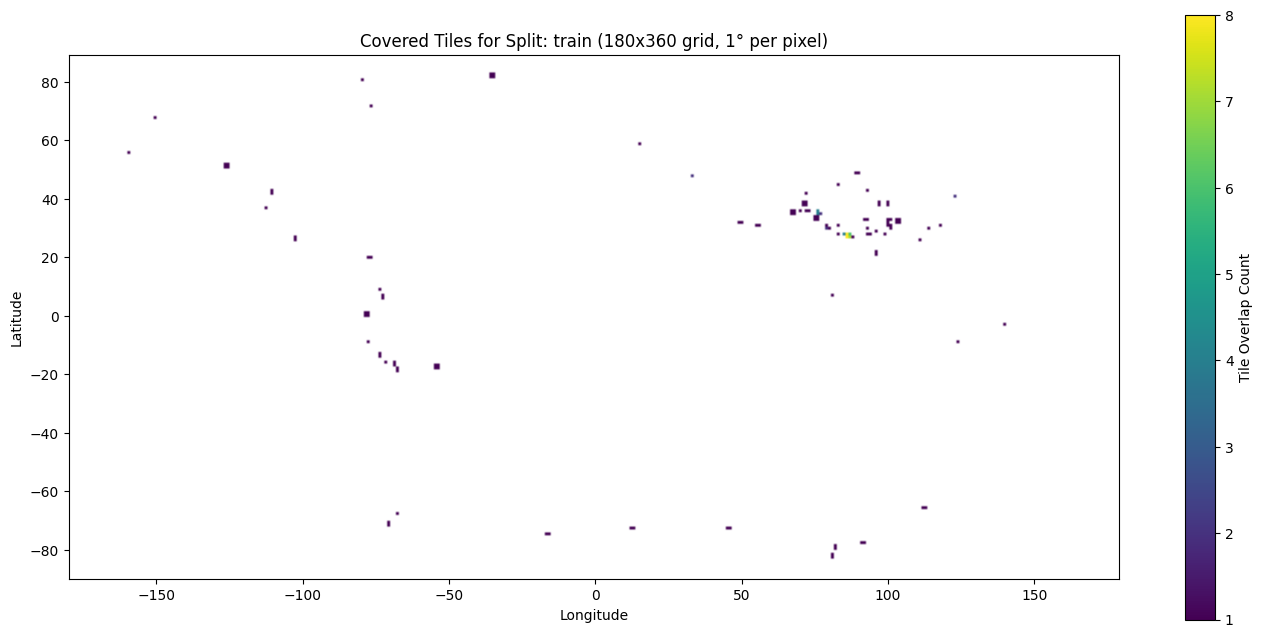

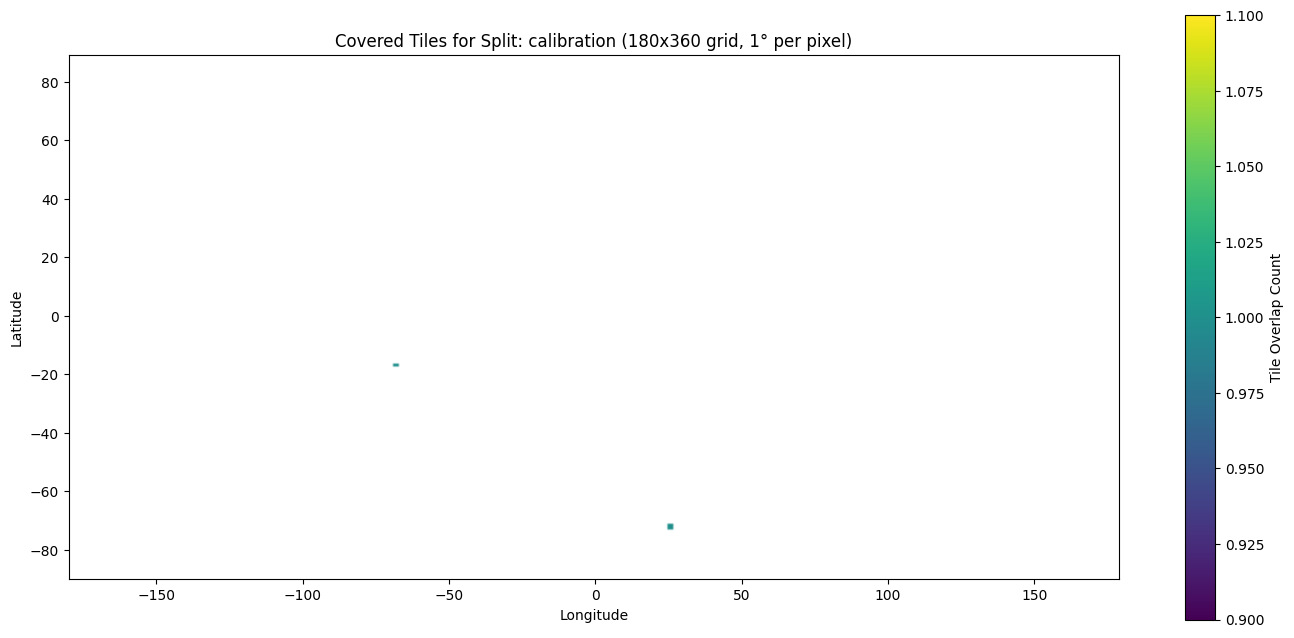

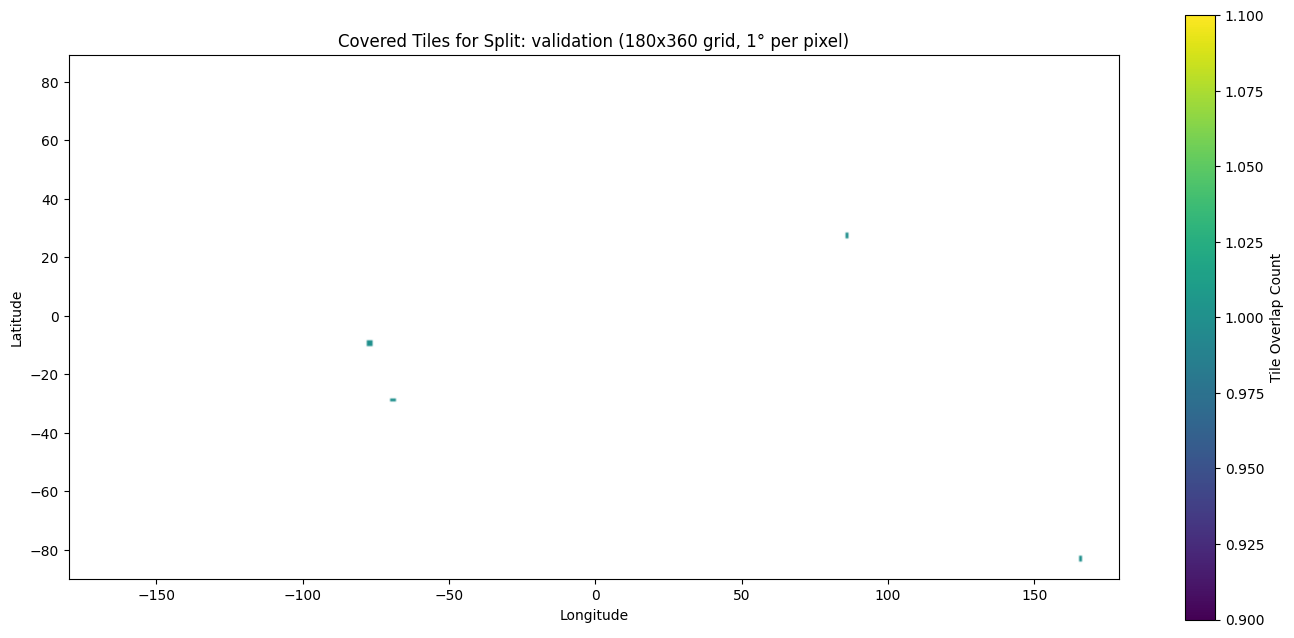

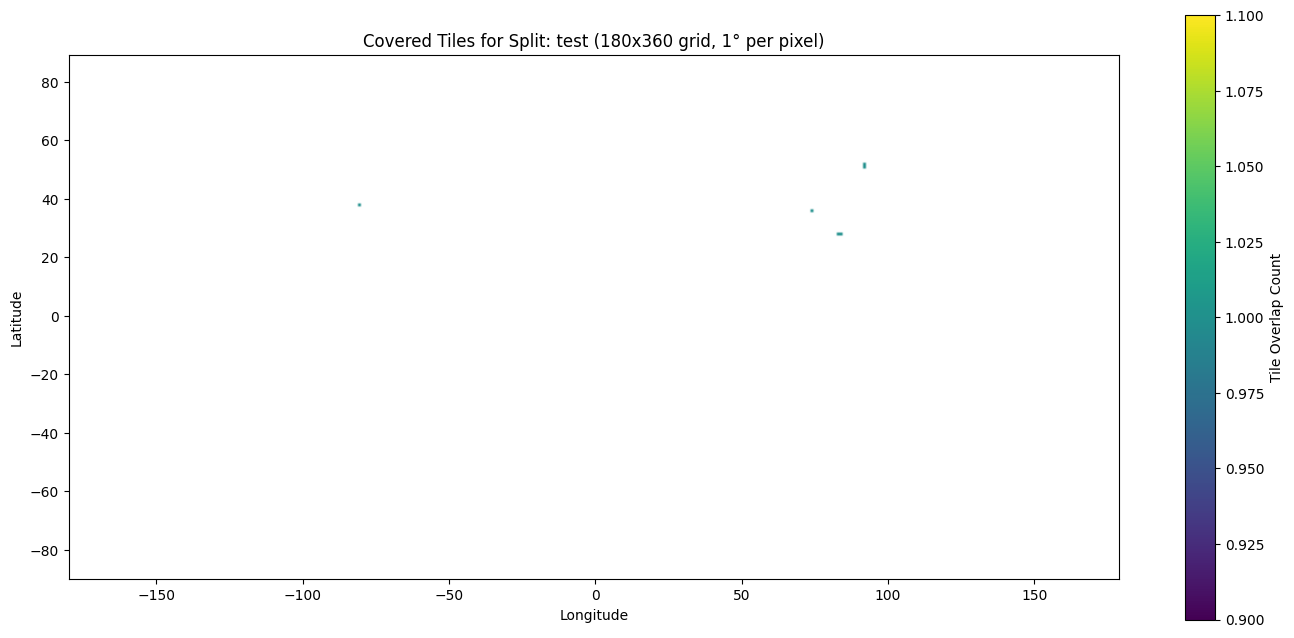

In [25]:
# Covered Tiles Visualization: build a 180x360 (1° per pixel) grid image from metadata overlapping tiles
# Zero-based full-globe grid: rows=180 (lat), cols=360 (lon); lat range [-90,89], lon range [-180,179]
for split, summary in splits.items():
    grid = np.zeros((180, 360), dtype=np.int32) * np.nan

    for (lat, lont), cell_info in summary["tiles_overlapping"].items():
        lat_i = int(lat)
        lon_j = int(lont)
        cnt = int(cell_info.get("count", 0))
        i = 89 - lat_i  # row 0 = northmost lat (89)
        j = lon_j + 180
        grid[i, j] = cnt

    fig = plt.figure(figsize=(14, 7))

    cmap = cm.viridis.copy()
    cmap.set_bad(color="white")  # zeros shown as white

    plt.imshow(grid, origin="upper", extent=[-180, 179, -90, 89], cmap=cmap, aspect="equal")
    plt.title(f"Covered Tiles for Split: {split} (180x360 grid, 1° per pixel)")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.tight_layout()
    plt.colorbar(label="Tile Overlap Count")
    plt.show()

## 4. Path Occurrence Heatmaps
Heatmaps aggregate pixel crossing counts across the dataset for each solver and path type:
- **Free paths**: computed without obstacles
- **Obstacles paths**: computed with obstacles

Each solver may produce different paths based on its cost model (elevation, energy, slope).

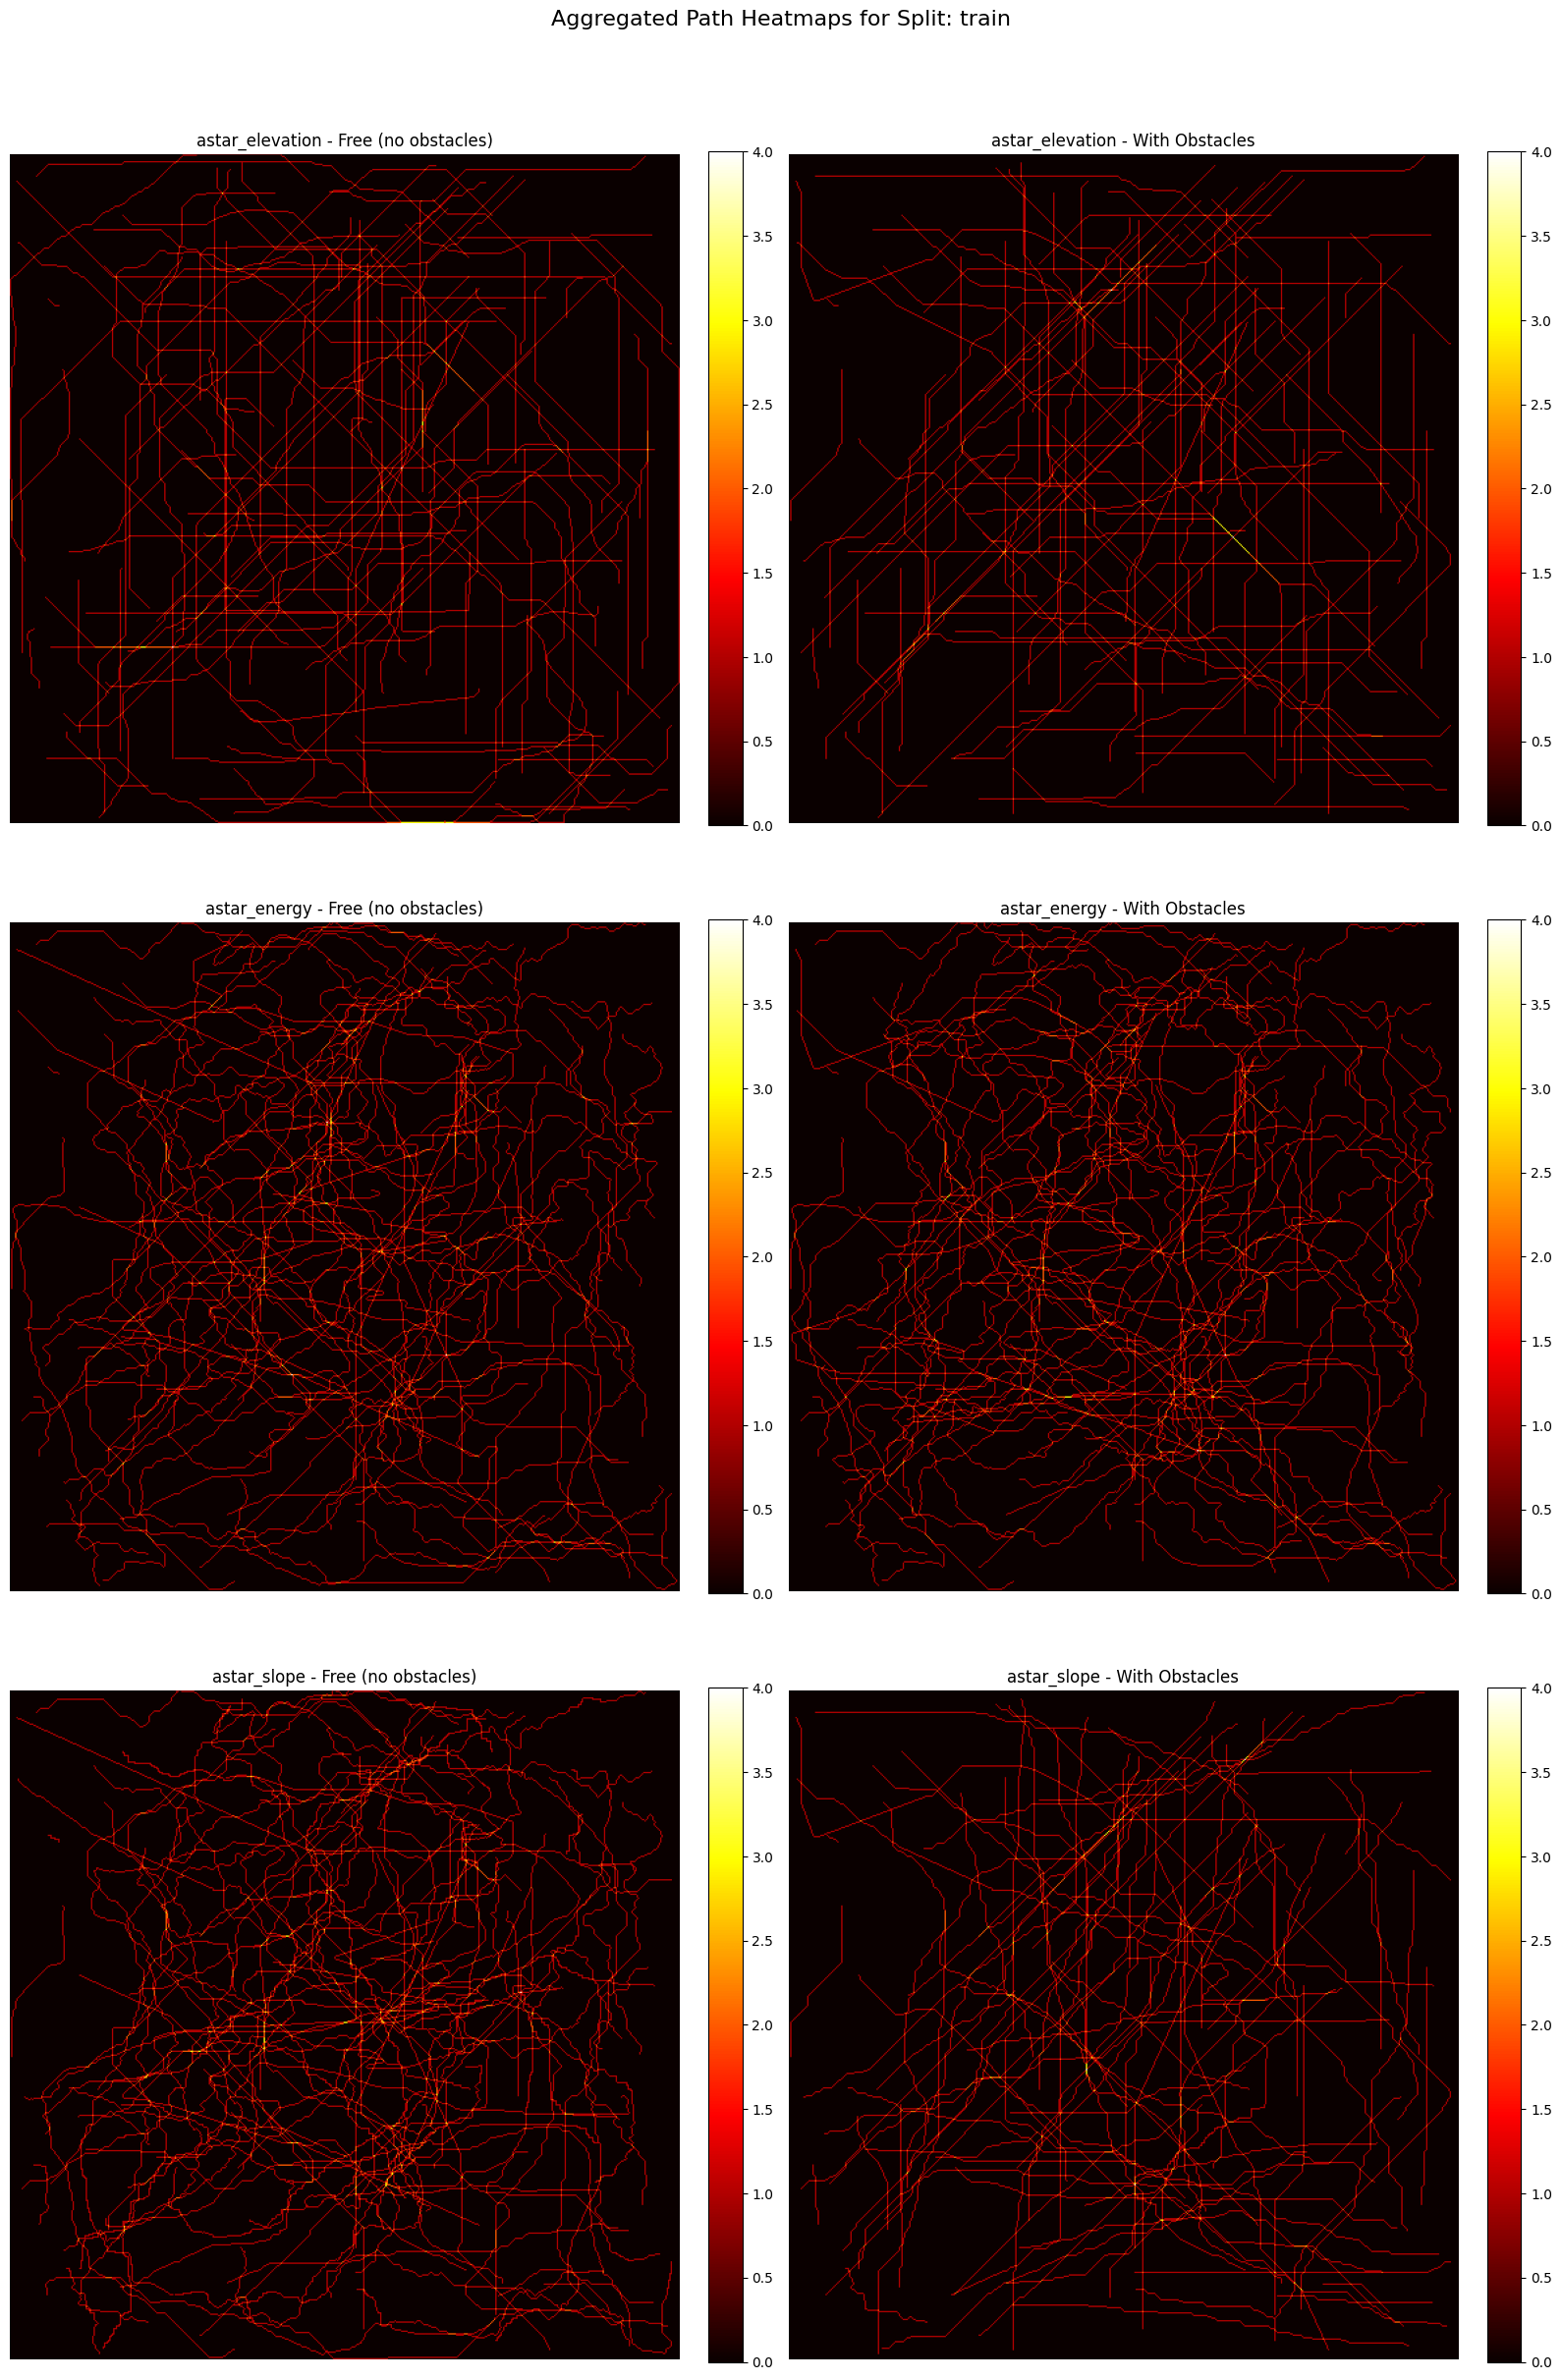

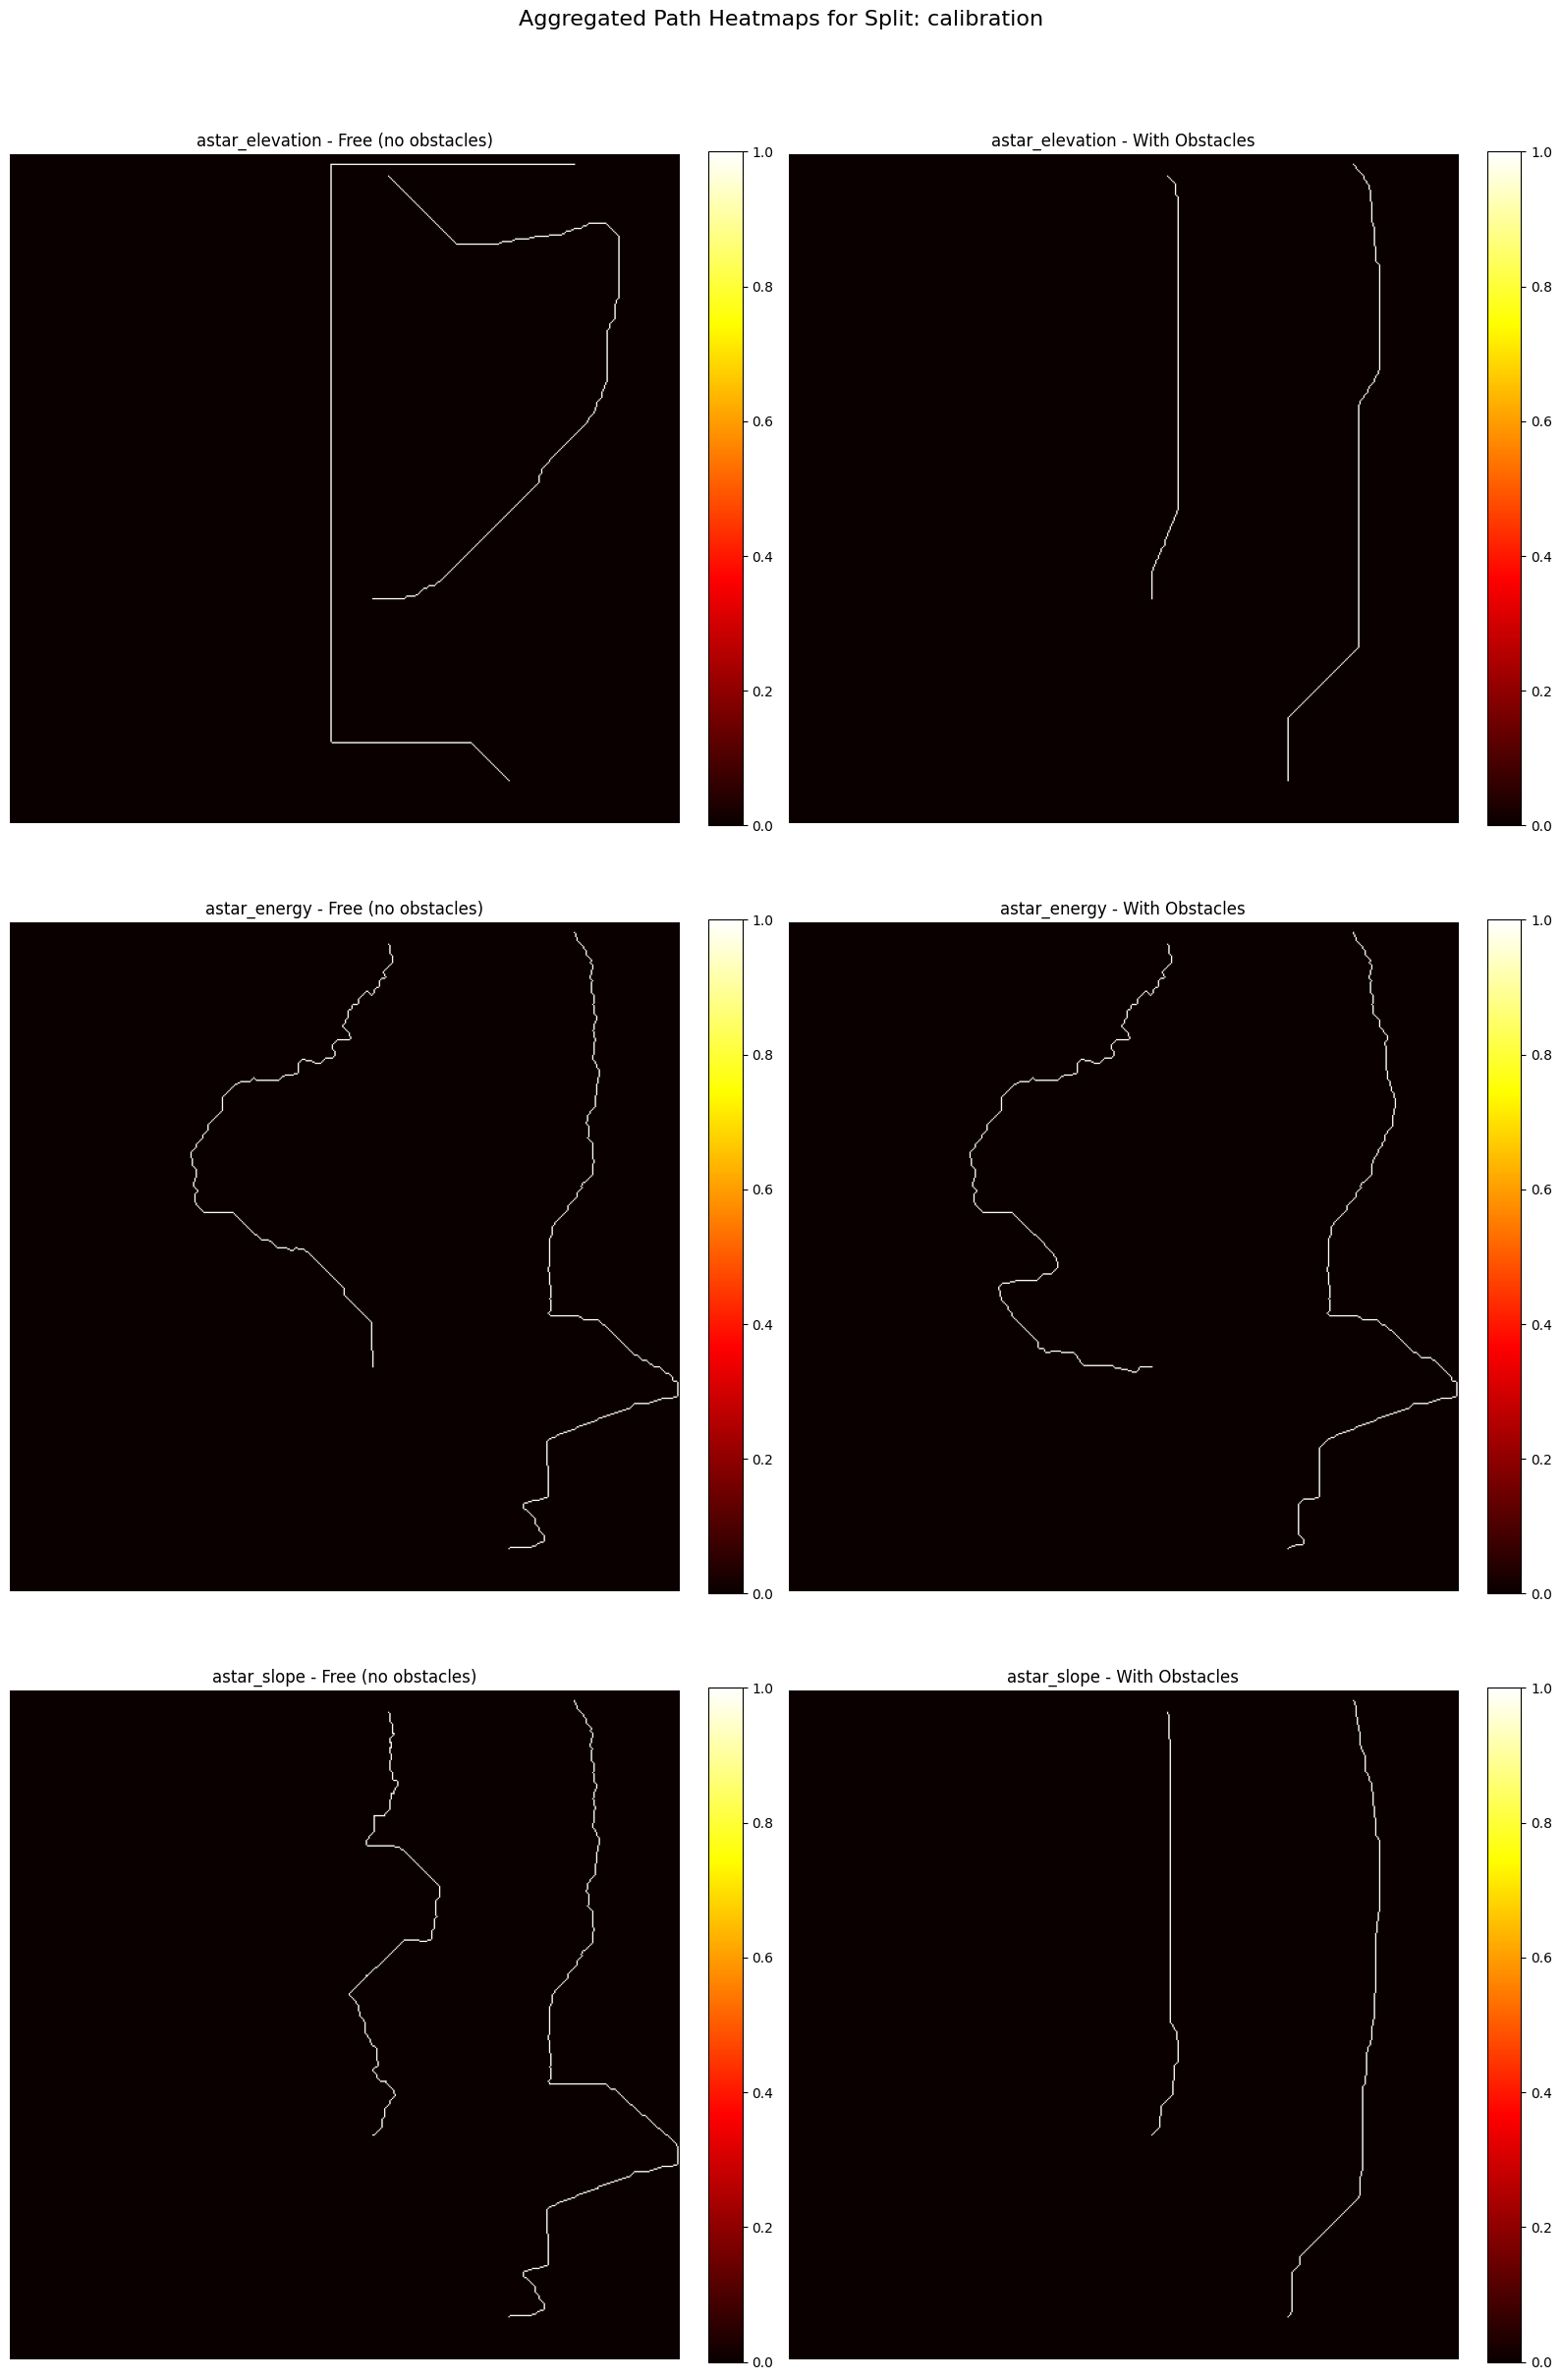

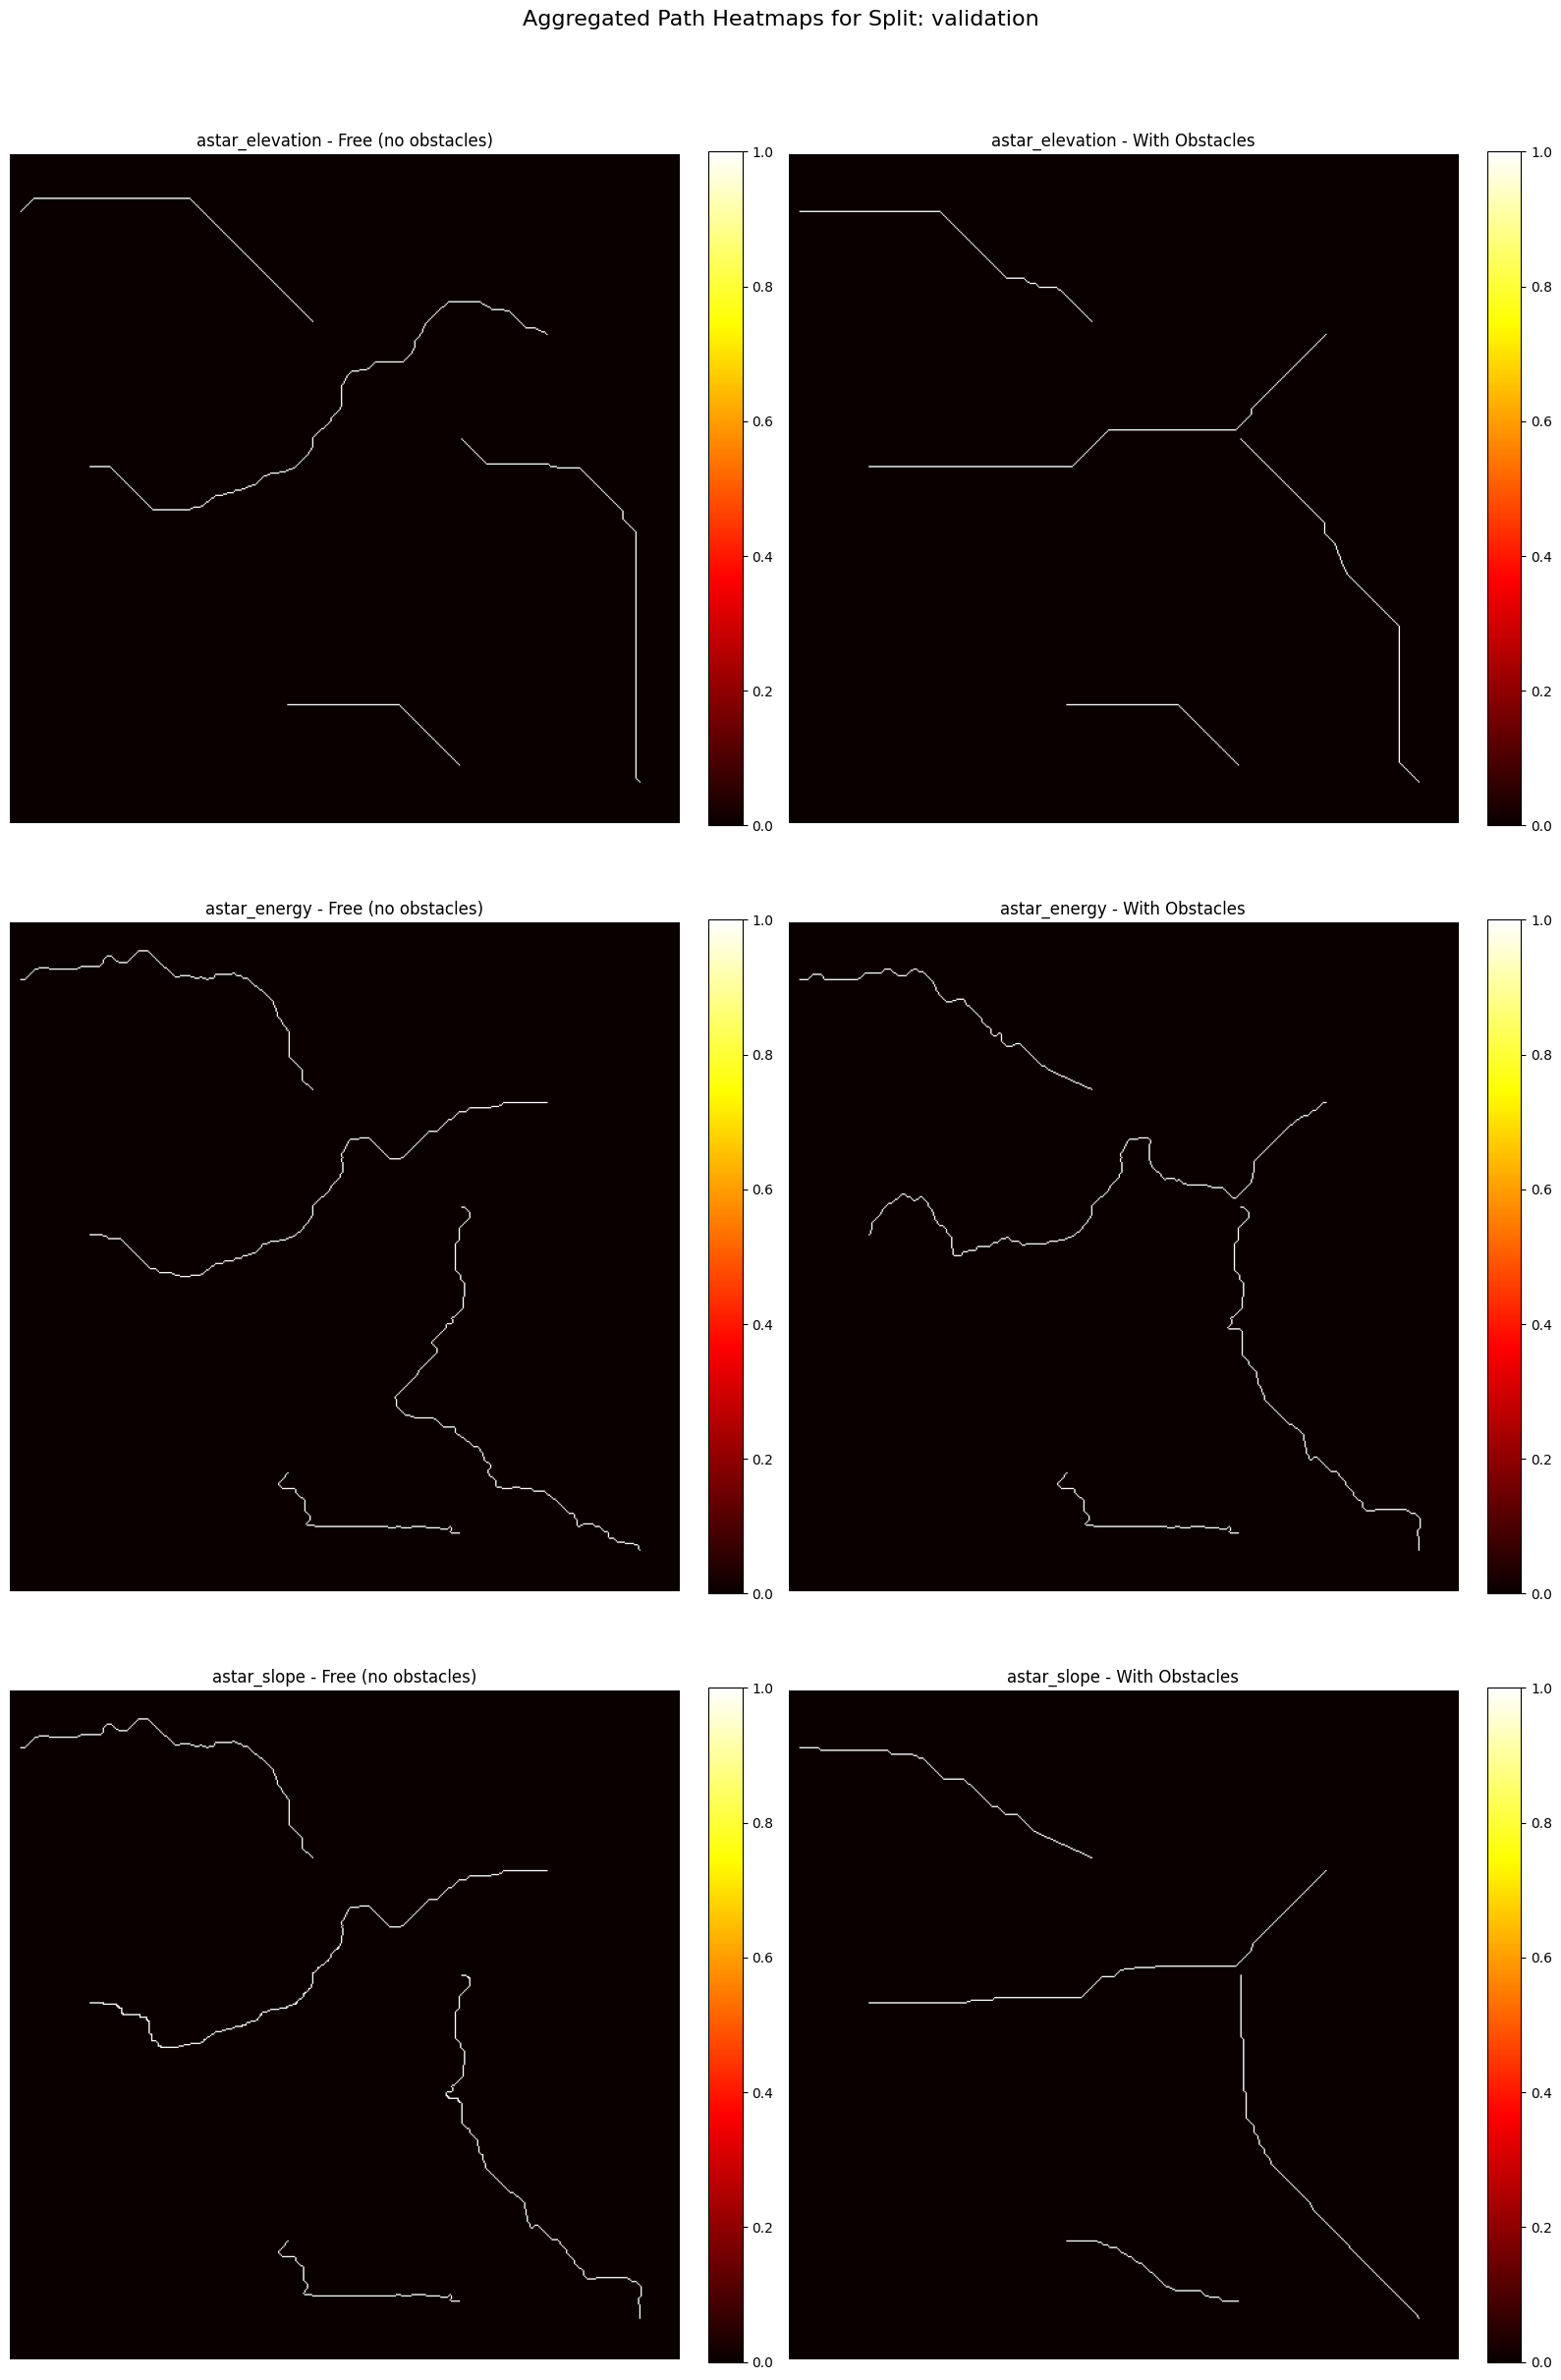

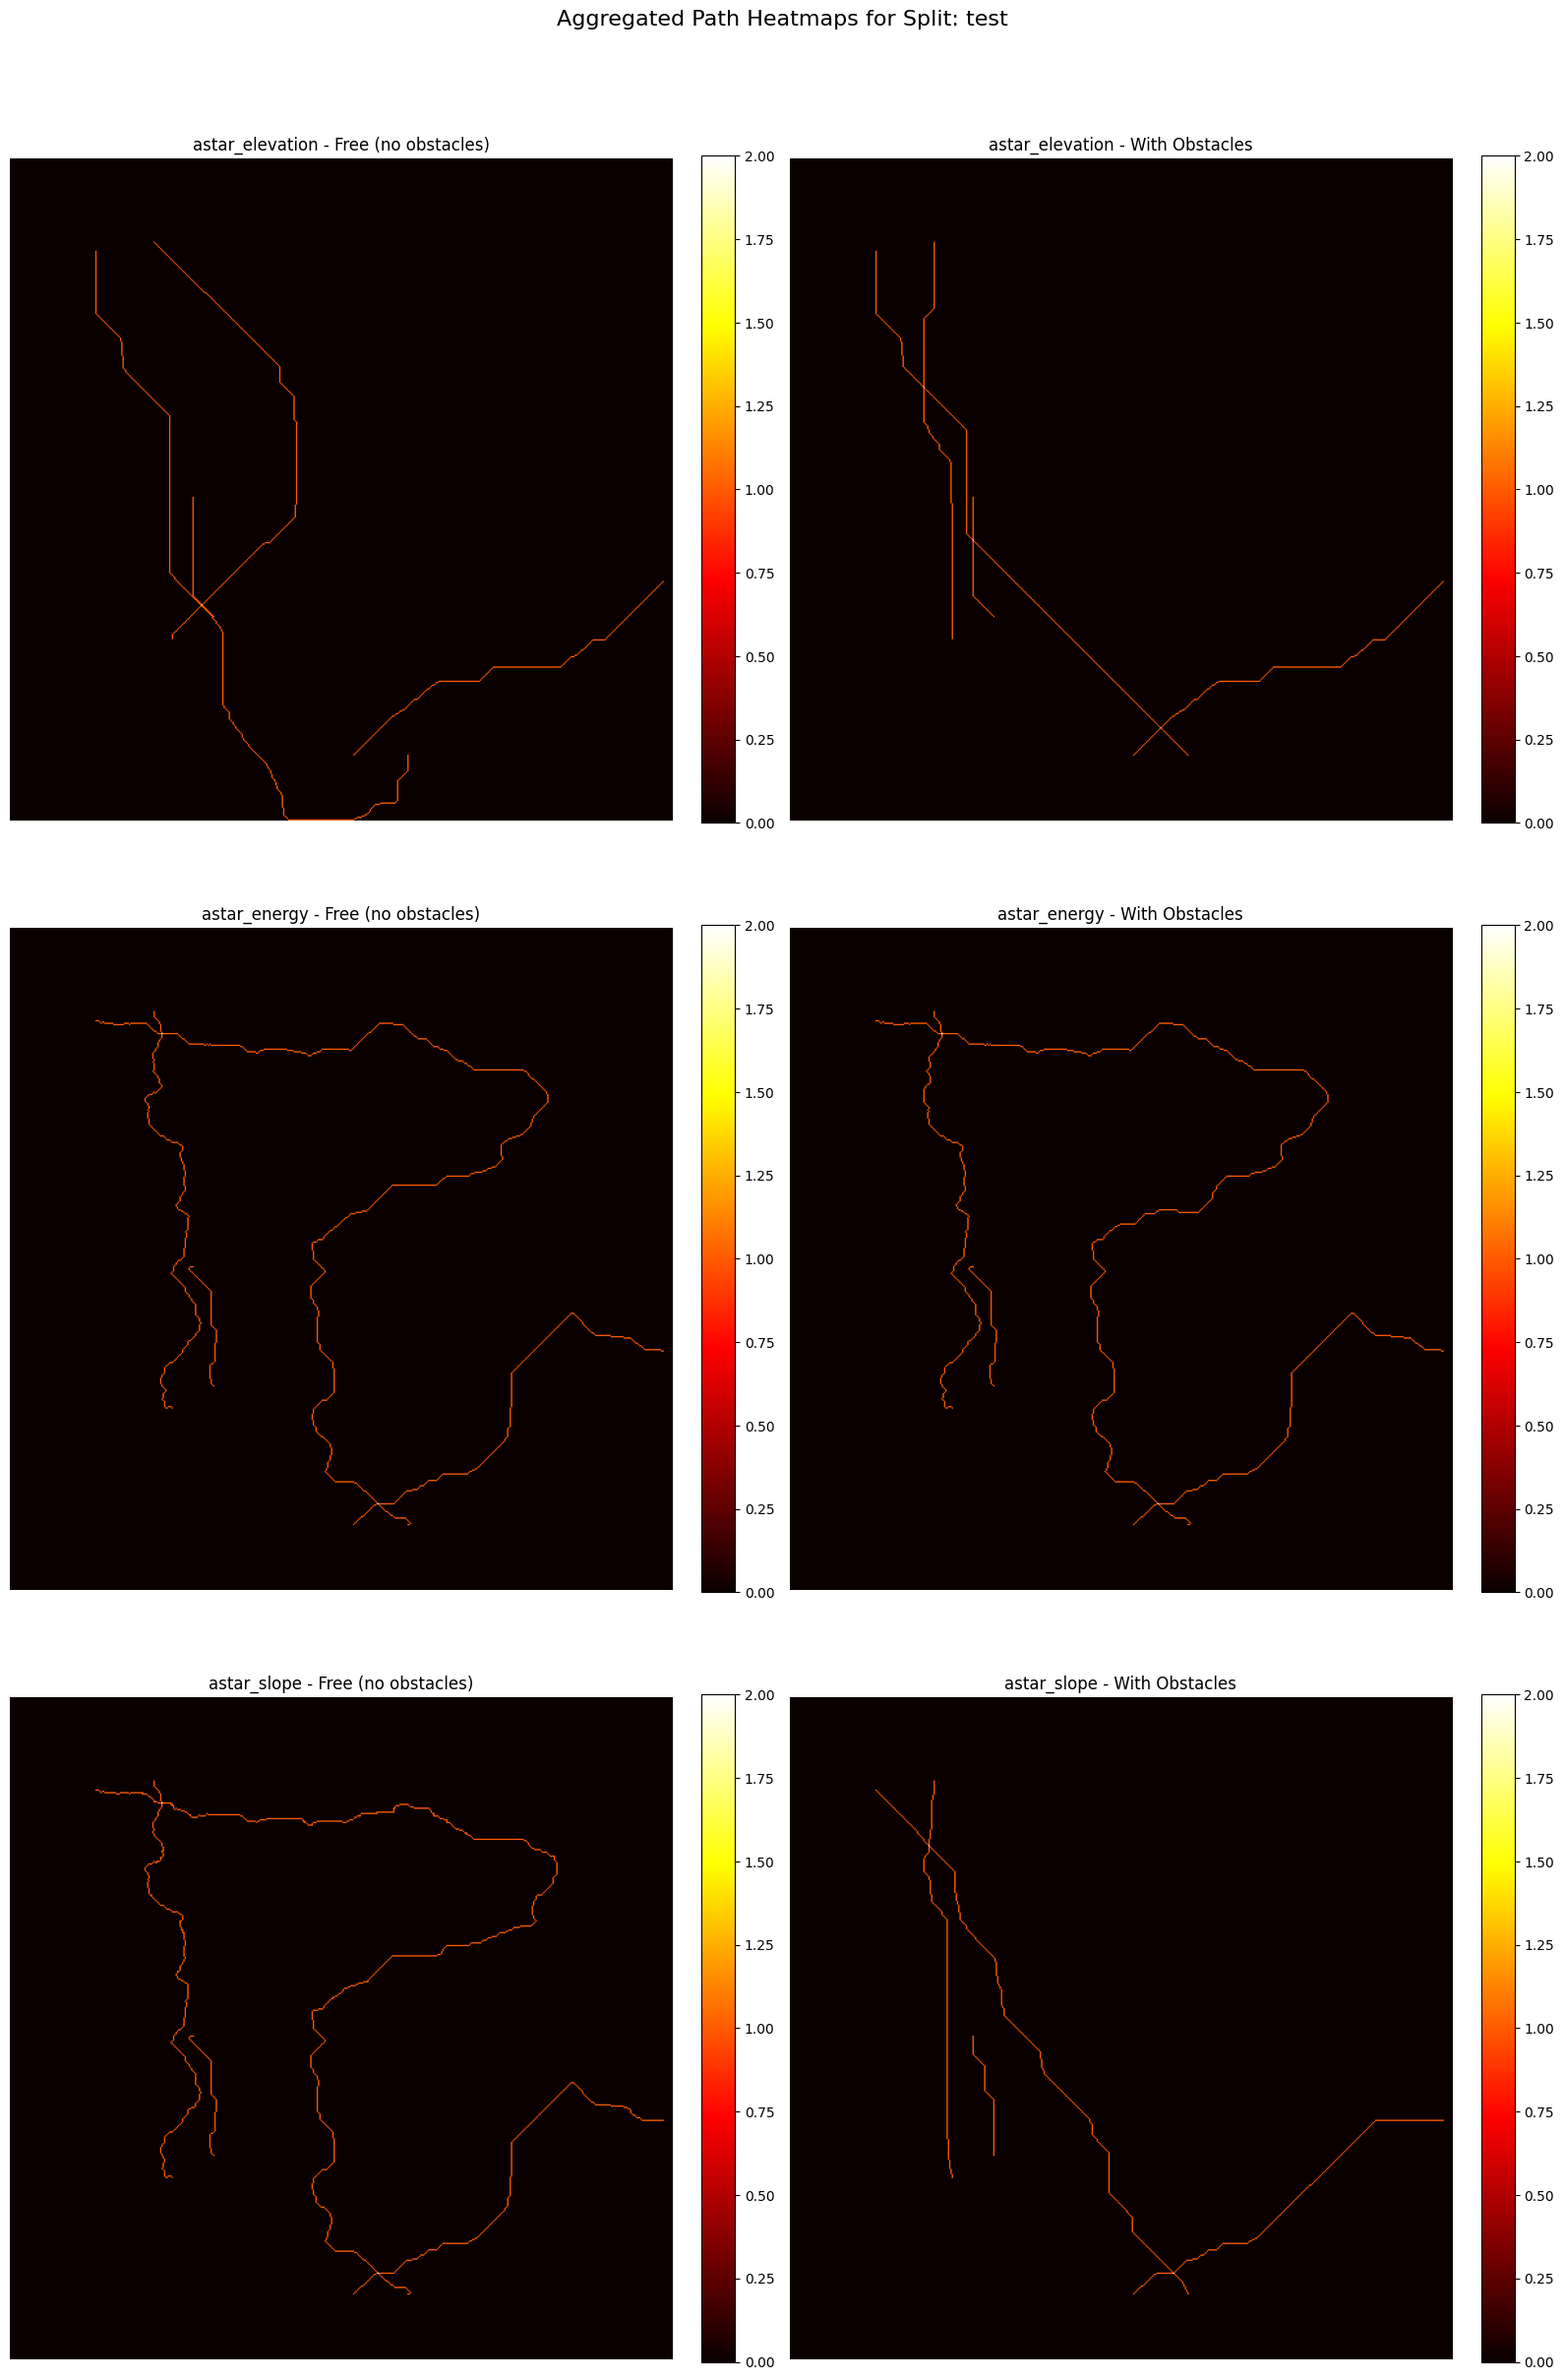

In [26]:
# Path occurrence heatmaps for each solver
for split, summary in splits.items():
    grids = summary["grids"]

    # Determine grid layout based on number of solvers
    n_solvers = len(SOLVER_NAMES)
    if n_solvers == 0:
        print(f"No solvers configured for split {split}")
        continue

    # Create a figure with 2 columns (free, obstacles) and n_solvers rows
    fig, axes = plt.subplots(n_solvers, 2, figsize=(16, 8 * n_solvers))
    if n_solvers == 1:
        axes = axes.reshape(1, 2)

    fig.suptitle(f"Aggregated Path Heatmaps for Split: {split}", fontsize=16, y=1.02)

    for idx, solver_name in enumerate(SOLVER_NAMES):
        # Free path
        free_key = f"{solver_name}_free"
        free_grid = grids.get(free_key, np.zeros((RESOLUTION, RESOLUTION)))
        ax_free = axes[idx, 0]
        im_free = ax_free.imshow(free_grid, cmap="hot", origin="upper")
        ax_free.set_title(f"{solver_name} - Free (no obstacles)")
        ax_free.axis("off")
        fig.colorbar(im_free, ax=ax_free, fraction=0.046, pad=0.04)

        # Obstacles path
        obs_key = f"{solver_name}_obstacles"
        obs_grid = grids.get(obs_key, np.zeros((RESOLUTION, RESOLUTION)))
        ax_obs = axes[idx, 1]
        im_obs = ax_obs.imshow(obs_grid, cmap="hot", origin="upper")
        ax_obs.set_title(f"{solver_name} - With Obstacles")
        ax_obs.axis("off")
        fig.colorbar(im_obs, ax=ax_obs, fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()

## 5. Start Point Elevation Distribution
Histogram of the absolute elevation at the first point of each obstacle-aware path.

Start point elevations (m): count=100, mean=4183.97, std=2894.12, min=-323.00, p25=1705.25, median=3830.50, p75=6987.50, max=8710.00


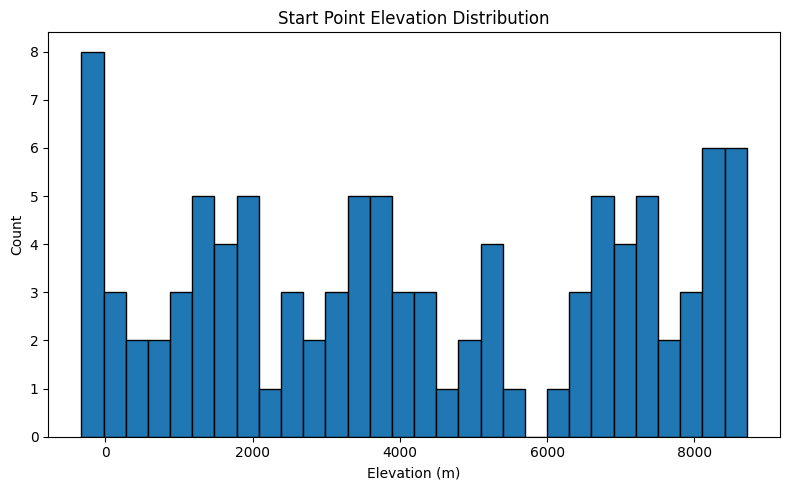

In [27]:
vals = [float(v) for v in start_elevations if v is not None]
if vals:
    describe_stats(vals, "Start point elevations (m)")
    plt.figure(figsize=(8, 5))
    plt.hist(vals, bins=30, edgecolor="black")
    plt.xlabel("Elevation (m)")
    plt.ylabel("Count")
    plt.title("Start Point Elevation Distribution")
    plt.tight_layout()
    plt.show()
else:
    print("No start elevations found; ensure metadata files are available.")

## 6. All Path Points Elevation Distribution
Histogram of all elevations visited by obstacle-aware paths.

All Path Point Elevations: count=24943, mean=3429.00, std=2263.32, min=-323.00, p25=1325.50, median=3643.00, p75=5395.00, max=8710.00


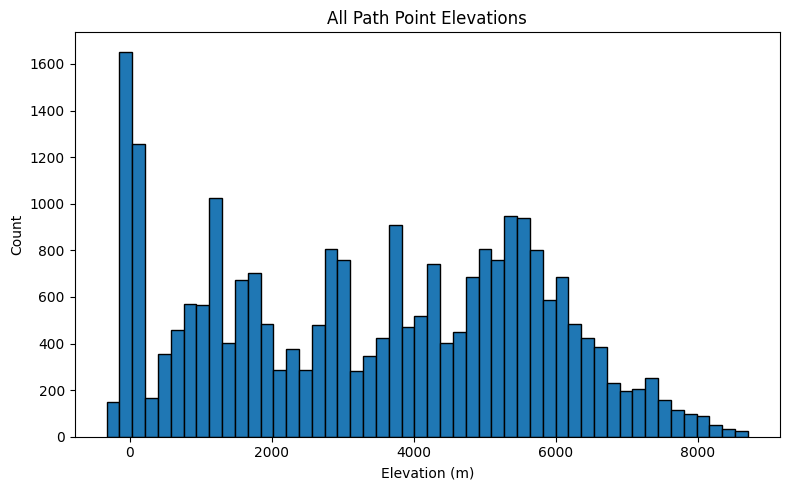

In [28]:
vals = [v for v in all_elevations if v is not None]
if vals:
    describe_stats(vals, "All Path Point Elevations")
    plt.figure(figsize=(8, 5))
    plt.hist(vals, bins=50, edgecolor="black")
    plt.xlabel("Elevation (m)")
    plt.ylabel("Count")
    plt.title("All Path Point Elevations")
    plt.tight_layout()
    plt.show()
else:
    print("No path elevation data available.")

## 7. Path Length Distribution (Per Solver)
Histogram of path lengths (number of pixels) for each solver, split by free (without obstacles) and obstacles (with obstacles) paths.

astar_elevation - Free Path Lengths (pixels): count=100, mean=285.89, std=153.06, min=9.00, p25=157.50, median=273.50, p75=388.50, max=764.00
astar_elevation - Obstacles Path Lengths (pixels): count=100, mean=249.43, std=122.12, min=9.00, p25=148.75, median=249.50, p75=338.25, max=578.00
astar_energy - Free Path Lengths (pixels): count=100, mean=324.03, std=180.55, min=9.00, p25=171.00, median=298.50, p75=449.50, max=916.00
astar_energy - Obstacles Path Lengths (pixels): count=100, mean=334.46, std=184.67, min=9.00, p25=188.25, median=318.50, p75=457.50, max=838.00
astar_slope - Free Path Lengths (pixels): count=100, mean=337.88, std=190.29, min=14.00, p25=199.25, median=315.50, p75=455.75, max=955.00
astar_slope - Obstacles Path Lengths (pixels): count=100, mean=251.87, std=123.63, min=9.00, p25=148.75, median=251.50, p75=340.00, max=578.00


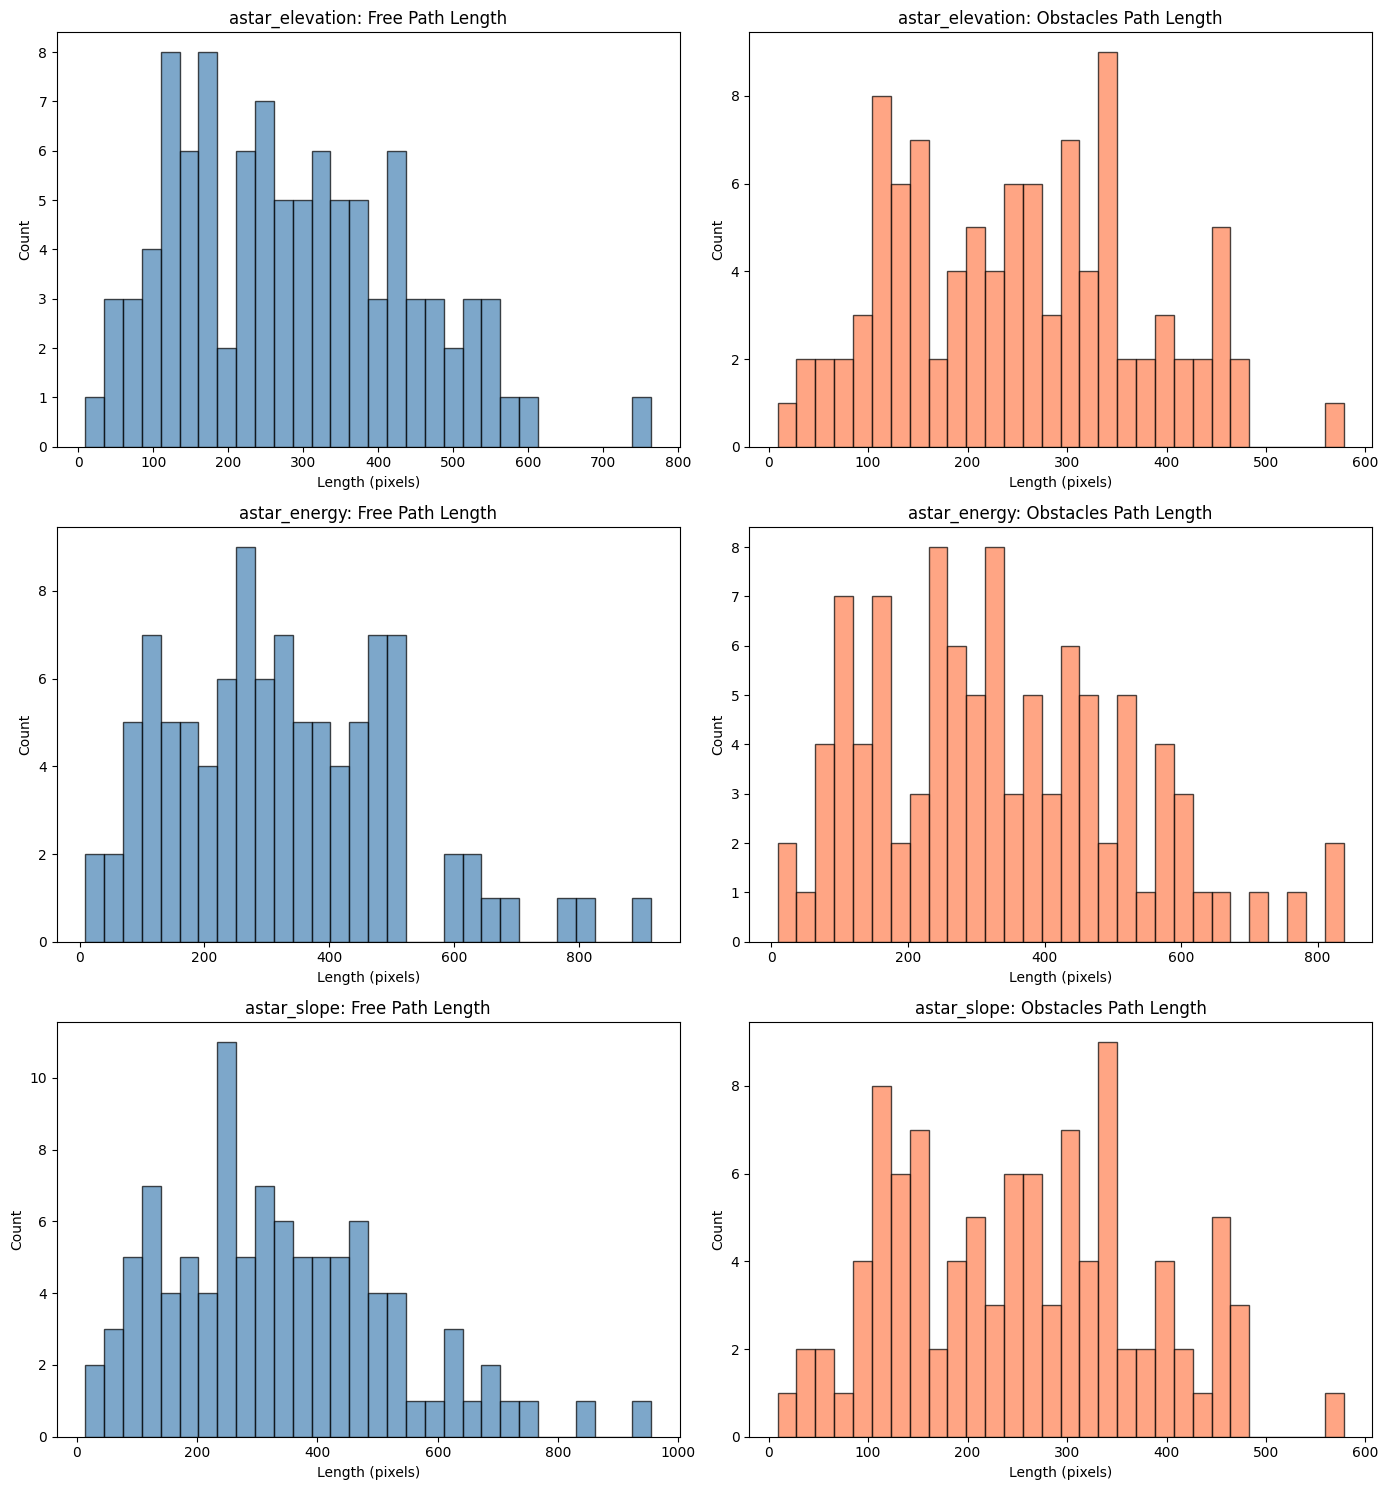

/tmp/ipykernel_405850/3957975368.py:44: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes2[0].boxplot([d for _, d in valid_free], labels=[s for s, _ in valid_free])
/tmp/ipykernel_405850/3957975368.py:52: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes2[1].boxplot([d for _, d in valid_obs], labels=[s for s, _ in valid_obs])


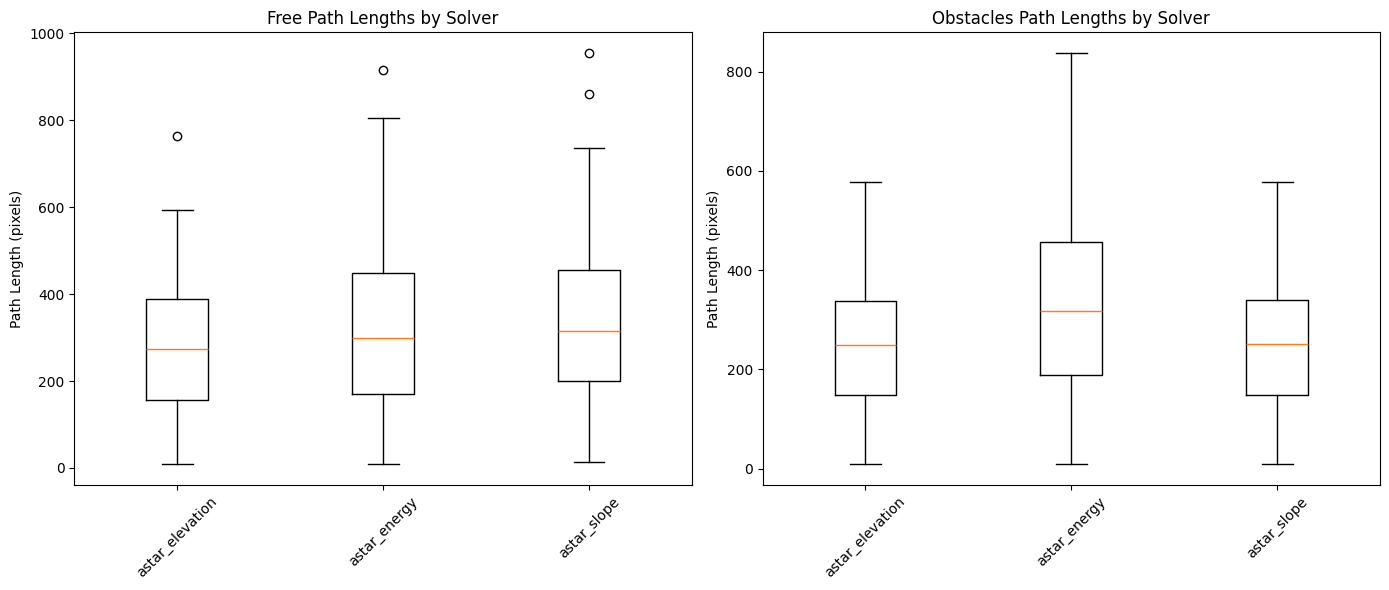

In [29]:
# Path length distribution per solver
n_solvers = len(SOLVER_NAMES)
if n_solvers == 0:
    print("No solvers configured.")
else:
    fig, axes = plt.subplots(n_solvers, 2, figsize=(14, 5 * n_solvers))
    if n_solvers == 1:
        axes = axes.reshape(1, 2)

    for idx, solver_name in enumerate(SOLVER_NAMES):
        # Free path lengths
        free_lengths = [v for v in solver_metrics[solver_name]["path_lengths_free"] if v is not None and v > 0]
        if free_lengths:
            describe_stats(free_lengths, f"{solver_name} - Free Path Lengths (pixels)")
            axes[idx, 0].hist(free_lengths, bins=30, edgecolor="black", alpha=0.7, color="steelblue")
            axes[idx, 0].set_xlabel("Length (pixels)")
            axes[idx, 0].set_ylabel("Count")
            axes[idx, 0].set_title(f"{solver_name}: Free Path Length")
        else:
            axes[idx, 0].text(0.5, 0.5, "No data", ha="center", va="center", transform=axes[idx, 0].transAxes)
            axes[idx, 0].set_title(f"{solver_name}: Free Path Length")

        # Obstacles path lengths
        obs_lengths = [v for v in solver_metrics[solver_name]["path_lengths_obstacles"] if v is not None and v > 0]
        if obs_lengths:
            describe_stats(obs_lengths, f"{solver_name} - Obstacles Path Lengths (pixels)")
            axes[idx, 1].hist(obs_lengths, bins=30, edgecolor="black", alpha=0.7, color="coral")
            axes[idx, 1].set_xlabel("Length (pixels)")
            axes[idx, 1].set_ylabel("Count")
            axes[idx, 1].set_title(f"{solver_name}: Obstacles Path Length")
        else:
            axes[idx, 1].text(0.5, 0.5, "No data", ha="center", va="center", transform=axes[idx, 1].transAxes)
            axes[idx, 1].set_title(f"{solver_name}: Obstacles Path Length")

    plt.tight_layout()
    plt.show()

    # Comparison box plot across solvers if multiple
    if n_solvers > 1:
        fig2, axes2 = plt.subplots(1, 2, figsize=(14, 6))
        free_data = [[v for v in solver_metrics[s]["path_lengths_free"] if v and v > 0] for s in SOLVER_NAMES]
        valid_free = [(s, d) for s, d in zip(SOLVER_NAMES, free_data) if d]
        if valid_free:
            axes2[0].boxplot([d for _, d in valid_free], labels=[s for s, _ in valid_free])
            axes2[0].set_ylabel("Path Length (pixels)")
            axes2[0].set_title("Free Path Lengths by Solver")
            axes2[0].tick_params(axis="x", rotation=45)

        obs_data = [[v for v in solver_metrics[s]["path_lengths_obstacles"] if v and v > 0] for s in SOLVER_NAMES]
        valid_obs = [(s, d) for s, d in zip(SOLVER_NAMES, obs_data) if d]
        if valid_obs:
            axes2[1].boxplot([d for _, d in valid_obs], labels=[s for s, _ in valid_obs])
            axes2[1].set_ylabel("Path Length (pixels)")
            axes2[1].set_title("Obstacles Path Lengths by Solver")
            axes2[1].tick_params(axis="x", rotation=45)

        plt.tight_layout()
        plt.show()

## 8. Normalized Relative Path Elevation Profile (Per Solver)
Each path elevation sequence is shifted by its start elevation and resampled to a common length $[0,1]$.
We plot the mean and standard deviation across samples for each solver, for both free and obstacles paths.

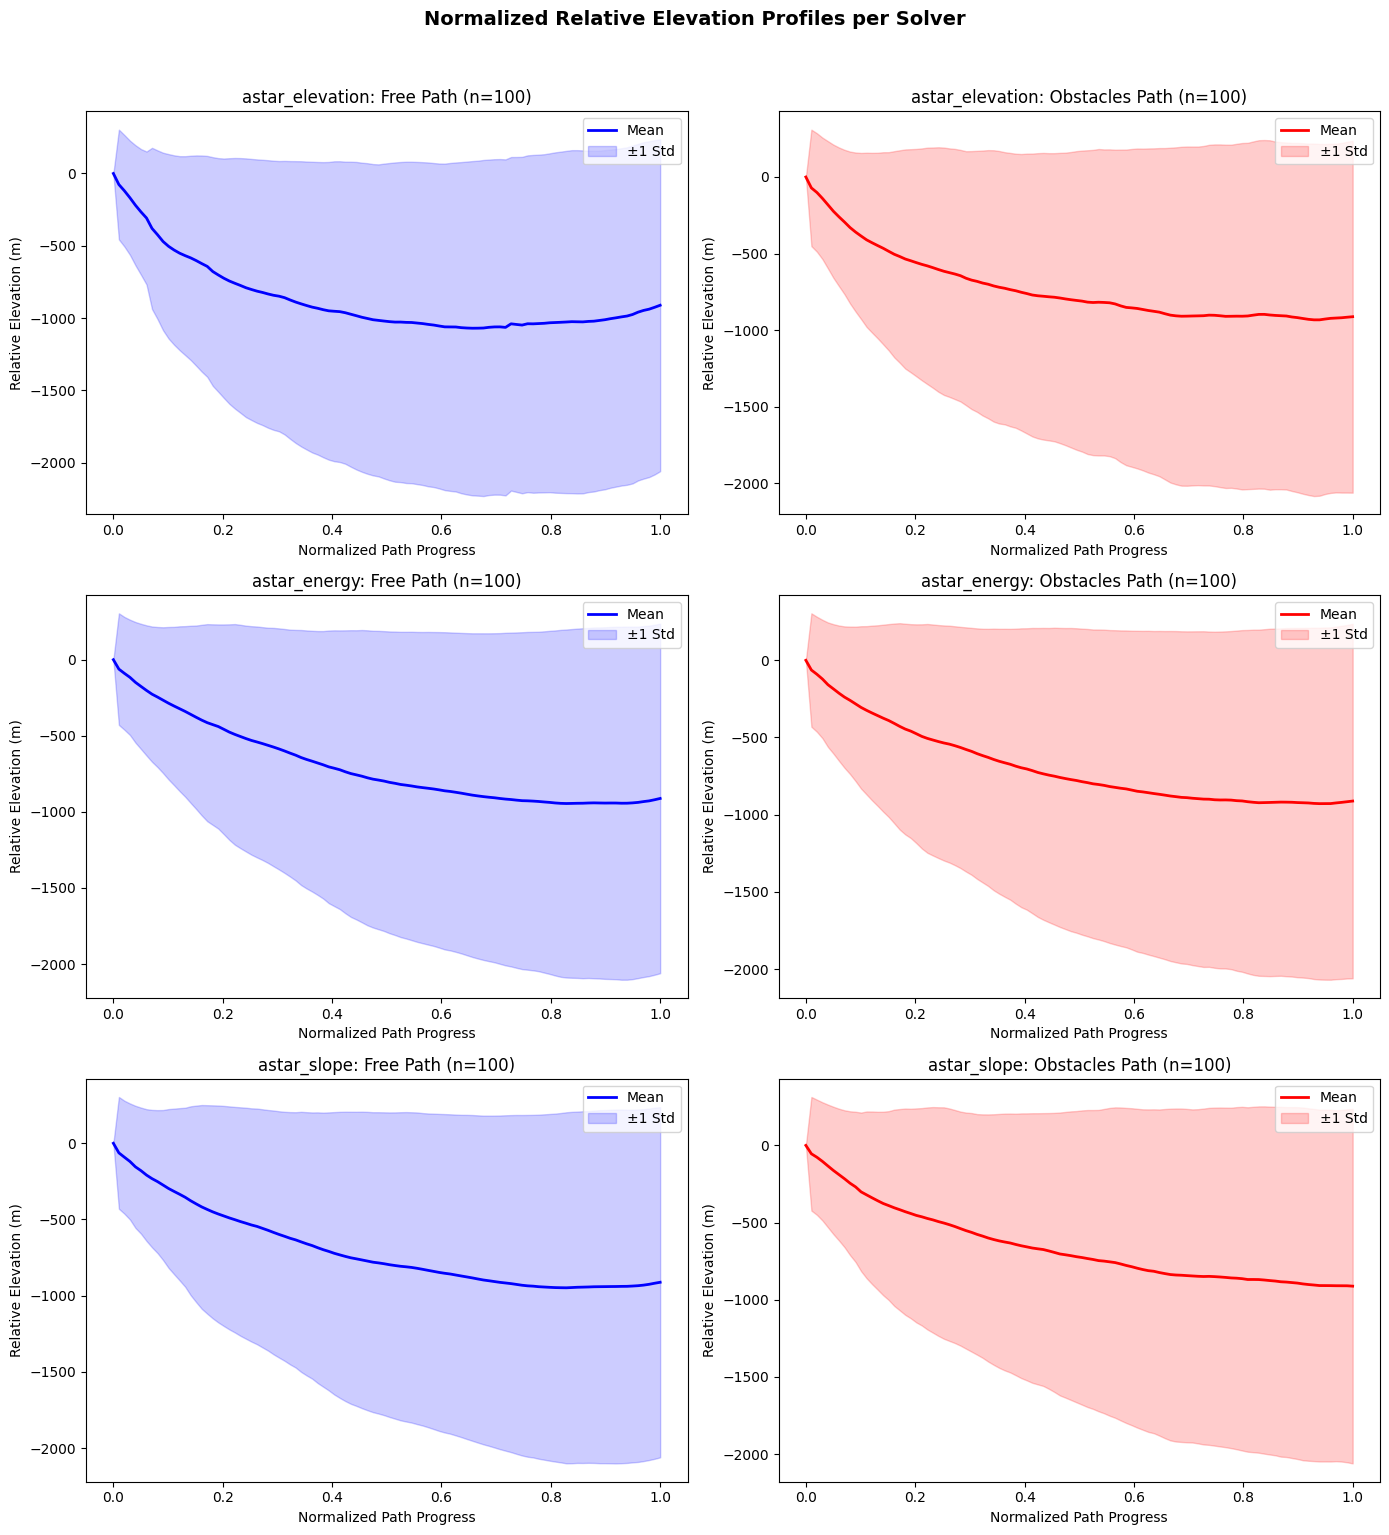


=== Elevation Profile Summary (Obstacles Path) ===


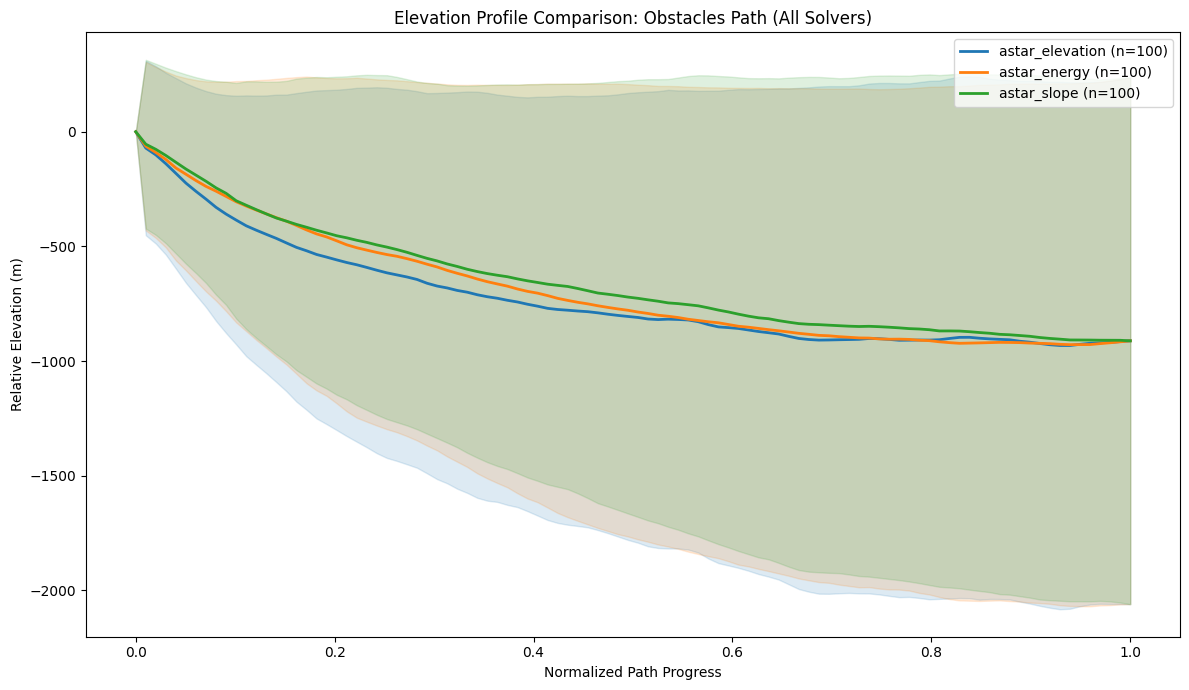

In [30]:
# Normalized relative path elevation profile per solver and path type
n_solvers = len(SOLVER_NAMES)
if n_solvers == 0:
    print("No solvers configured.")
else:
    # Create subplot grid for each solver: one row per solver, two columns (free, obstacles)
    fig, axes = plt.subplots(n_solvers, 2, figsize=(14, 5 * n_solvers), squeeze=False)

    for idx, solver_name in enumerate(SOLVER_NAMES):
        profiles_free = solver_metrics[solver_name].get("profiles_free", [])
        profiles_obs = solver_metrics[solver_name].get("profiles_obstacles", [])

        # Plot Free path profiles
        ax_free = axes[idx, 0]
        if profiles_free:
            profiles_arr = np.array(profiles_free, dtype=np.float64)
            mean_profile = np.mean(profiles_arr, axis=0)
            std_profile = np.std(profiles_arr, axis=0)
            x_axis = np.linspace(0, 1, profiles_arr.shape[1])

            ax_free.plot(x_axis, mean_profile, "b-", linewidth=2, label="Mean")
            ax_free.fill_between(
                x_axis, mean_profile - std_profile, mean_profile + std_profile, alpha=0.2, color="blue", label="±1 Std"
            )
            ax_free.set_xlabel("Normalized Path Progress")
            ax_free.set_ylabel("Relative Elevation (m)")
            ax_free.set_title(f"{solver_name}: Free Path (n={len(profiles_free)})")
            ax_free.legend(loc="upper right")
        else:
            ax_free.text(0.5, 0.5, "No elevation data", ha="center", va="center", transform=ax_free.transAxes)
            ax_free.set_title(f"{solver_name}: Free Path")

        # Plot Obstacles path profiles
        ax_obs = axes[idx, 1]
        if profiles_obs:
            profiles_arr = np.array(profiles_obs, dtype=np.float64)
            mean_profile = np.mean(profiles_arr, axis=0)
            std_profile = np.std(profiles_arr, axis=0)
            x_axis = np.linspace(0, 1, profiles_arr.shape[1])

            ax_obs.plot(x_axis, mean_profile, "r-", linewidth=2, label="Mean")
            ax_obs.fill_between(
                x_axis, mean_profile - std_profile, mean_profile + std_profile, alpha=0.2, color="red", label="±1 Std"
            )
            ax_obs.set_xlabel("Normalized Path Progress")
            ax_obs.set_ylabel("Relative Elevation (m)")
            ax_obs.set_title(f"{solver_name}: Obstacles Path (n={len(profiles_obs)})")
            ax_obs.legend(loc="upper right")
        else:
            ax_obs.text(0.5, 0.5, "No elevation data", ha="center", va="center", transform=ax_obs.transAxes)
            ax_obs.set_title(f"{solver_name}: Obstacles Path")

    plt.suptitle("Normalized Relative Elevation Profiles per Solver", fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

    # Summary overlay: all solvers on one plot for comparison
    print("\n=== Elevation Profile Summary (Obstacles Path) ===")
    fig2, ax2 = plt.subplots(figsize=(12, 7))
    colors = plt.cm.tab10.colors
    has_any_data = False
    for idx, solver_name in enumerate(SOLVER_NAMES):
        profiles_obs = solver_metrics[solver_name].get("profiles_obstacles", [])
        if profiles_obs:
            has_any_data = True
            profiles_arr = np.array(profiles_obs, dtype=np.float64)
            mean_profile = np.mean(profiles_arr, axis=0)
            std_profile = np.std(profiles_arr, axis=0)
            x_axis = np.linspace(0, 1, profiles_arr.shape[1])
            color = colors[idx % len(colors)]
            ax2.plot(x_axis, mean_profile, linewidth=2, label=f"{solver_name} (n={len(profiles_obs)})", color=color)
            ax2.fill_between(x_axis, mean_profile - std_profile, mean_profile + std_profile, alpha=0.15, color=color)

    if has_any_data:
        ax2.set_xlabel("Normalized Path Progress")
        ax2.set_ylabel("Relative Elevation (m)")
        ax2.set_title("Elevation Profile Comparison: Obstacles Path (All Solvers)")
        ax2.legend(loc="upper right")
        plt.tight_layout()
        plt.show()
    else:
        print("No elevation profile data available for any solver.")

## 9. Hausdorff Distance: Free Path vs. Straight Line (Per Solver)
Normalized Hausdorff distance between the free (no-obstacle) path and the straight-line path between markers for each solver. This measures how much terrain elevation causes deviations from a straight line.

astar_elevation - Hausdorff (Free vs Straight): count=100, mean=0.20, std=0.15, min=0.01, p25=0.10, median=0.16, p75=0.24, max=0.84
astar_energy - Hausdorff (Free vs Straight): count=100, mean=0.22, std=0.16, min=0.03, p25=0.11, median=0.17, p75=0.30, max=0.95
astar_slope - Hausdorff (Free vs Straight): count=100, mean=0.22, std=0.15, min=0.02, p25=0.11, median=0.17, p75=0.29, max=0.95


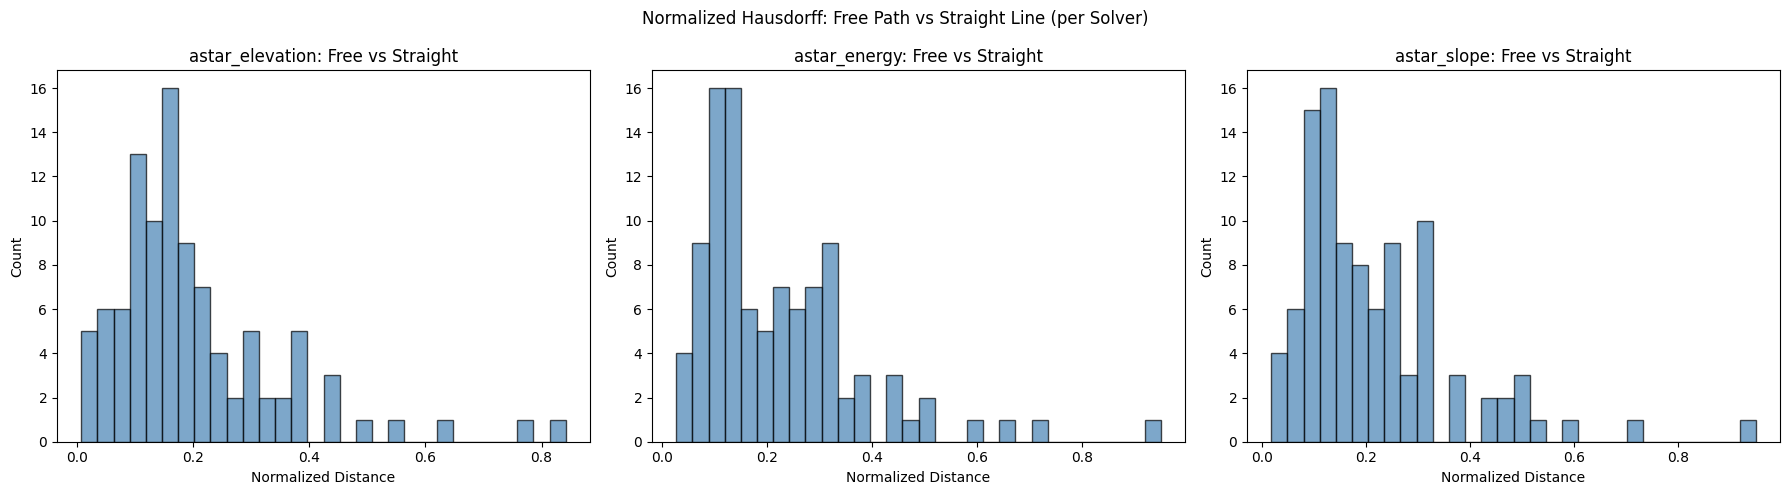

/tmp/ipykernel_405850/1292299133.py:39: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([d for _, d in valid], labels=[s for s, _ in valid])


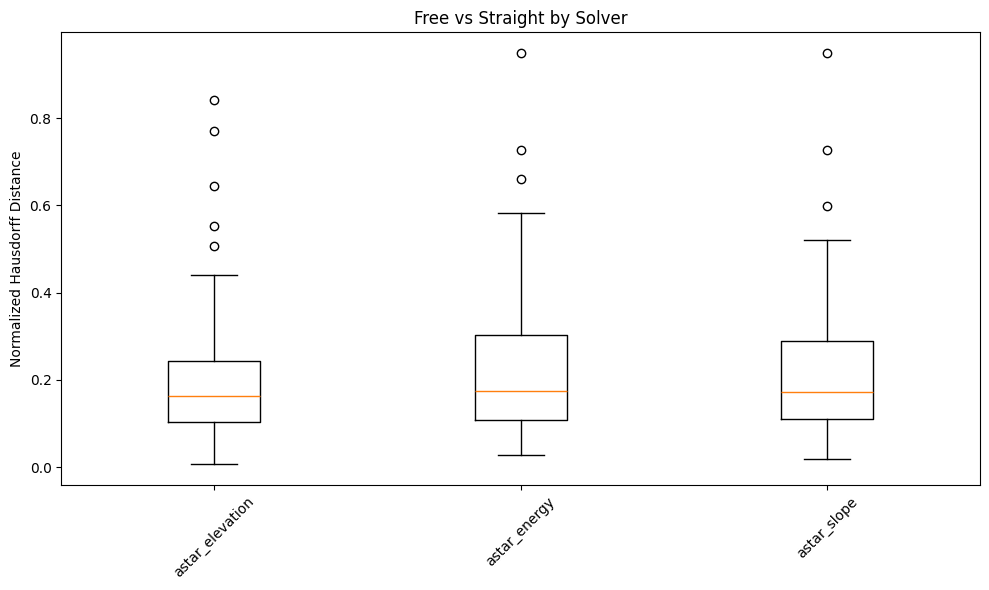

In [31]:
# Hausdorff distance: Free path vs Straight line (per solver)
n_solvers = len(SOLVER_NAMES)
if n_solvers == 0:
    print("No solvers configured.")
else:
    n_cols = min(3, n_solvers)
    n_rows = math.ceil(n_solvers / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
    if n_solvers == 1:
        axes = np.array([axes])
    axes = axes.flatten()

    for idx, solver_name in enumerate(SOLVER_NAMES):
        h_vals = [v for v in solver_metrics[solver_name]["hausdorff_free_straight"] if v is not None and v > 0]
        if h_vals:
            describe_stats(h_vals, f"{solver_name} - Hausdorff (Free vs Straight)")
            axes[idx].hist(h_vals, bins=30, edgecolor="black", alpha=0.7, color="steelblue")
            axes[idx].set_xlabel("Normalized Distance")
            axes[idx].set_ylabel("Count")
            axes[idx].set_title(f"{solver_name}: Free vs Straight")
        else:
            axes[idx].text(0.5, 0.5, "No data", ha="center", va="center", transform=axes[idx].transAxes)
            axes[idx].set_title(f"{solver_name}: Free vs Straight")

    # Hide unused axes
    for idx in range(n_solvers, len(axes)):
        axes[idx].axis("off")

    plt.suptitle("Normalized Hausdorff: Free Path vs Straight Line (per Solver)")
    plt.tight_layout()
    plt.show()

    # Comparison box plot across solvers if multiple
    if n_solvers > 1:
        fig2, ax = plt.subplots(figsize=(10, 6))
        h_data = [
            [v for v in solver_metrics[s]["hausdorff_free_straight"] if v is not None and v > 0] for s in SOLVER_NAMES
        ]
        valid = [(s, d) for s, d in zip(SOLVER_NAMES, h_data) if d]
        if valid:
            ax.boxplot([d for _, d in valid], labels=[s for s, _ in valid])
            ax.set_ylabel("Normalized Hausdorff Distance")
            ax.set_title("Free vs Straight by Solver")
            ax.tick_params(axis="x", rotation=45)
            plt.tight_layout()
            plt.show()

## 10. Hausdorff Distance: Obstacles vs. Free Path (Per Solver)
Normalized Hausdorff distance between the obstacle-aware path and the free (no-obstacle) path for each solver. This measures the deviation introduced specifically by obstacles.

astar_elevation - Hausdorff (Obstacles vs Free): count=78, mean=0.19, std=0.17, min=0.01, p25=0.08, median=0.15, p75=0.26, max=0.83
astar_energy - Hausdorff (Obstacles vs Free): count=45, mean=0.18, std=0.14, min=0.00, p25=0.05, median=0.15, p75=0.28, max=0.48
astar_slope - Hausdorff (Obstacles vs Free): count=94, mean=0.21, std=0.16, min=0.01, p25=0.09, median=0.19, p75=0.28, max=0.95


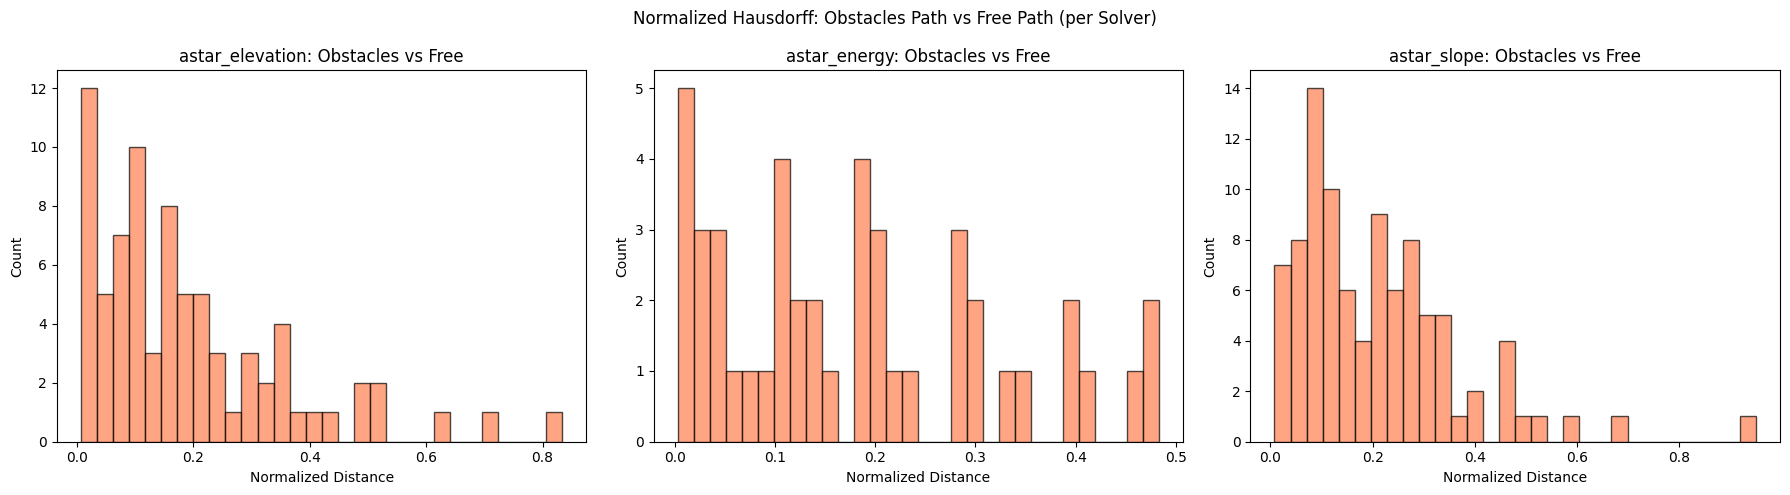

/tmp/ipykernel_405850/276663442.py:39: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([d for _, d in valid], labels=[s for s, _ in valid])


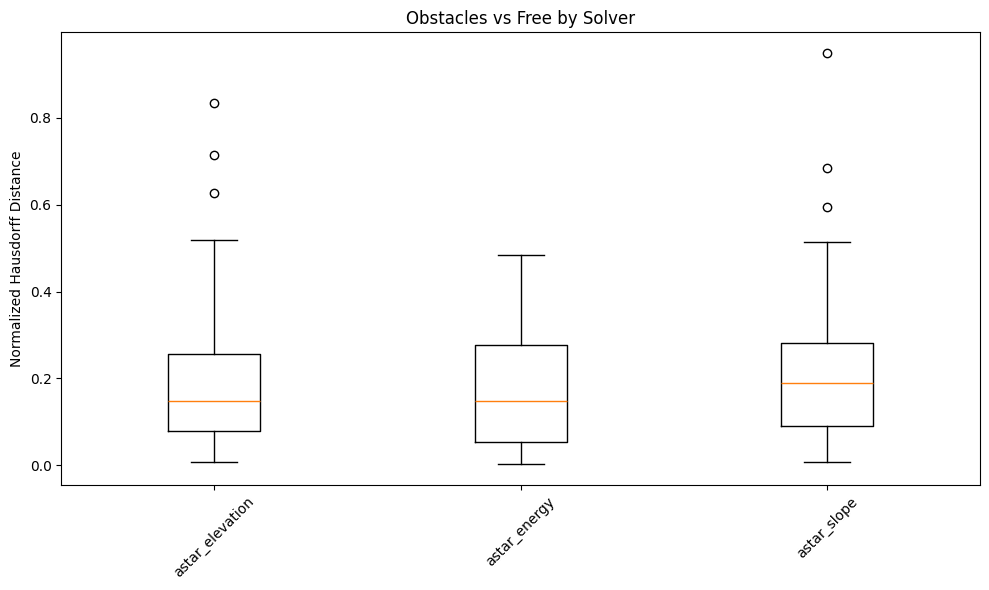

In [32]:
# Hausdorff distance: Obstacles path vs Free path (per solver)
n_solvers = len(SOLVER_NAMES)
if n_solvers == 0:
    print("No solvers configured.")
else:
    n_cols = min(3, n_solvers)
    n_rows = math.ceil(n_solvers / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
    if n_solvers == 1:
        axes = np.array([axes])
    axes = axes.flatten()

    for idx, solver_name in enumerate(SOLVER_NAMES):
        h_vals = [v for v in solver_metrics[solver_name]["hausdorff_obs_free"] if v is not None and v > 0]
        if h_vals:
            describe_stats(h_vals, f"{solver_name} - Hausdorff (Obstacles vs Free)")
            axes[idx].hist(h_vals, bins=30, edgecolor="black", alpha=0.7, color="coral")
            axes[idx].set_xlabel("Normalized Distance")
            axes[idx].set_ylabel("Count")
            axes[idx].set_title(f"{solver_name}: Obstacles vs Free")
        else:
            axes[idx].text(0.5, 0.5, "No data", ha="center", va="center", transform=axes[idx].transAxes)
            axes[idx].set_title(f"{solver_name}: Obstacles vs Free")

    # Hide unused axes
    for idx in range(n_solvers, len(axes)):
        axes[idx].axis("off")

    plt.suptitle("Normalized Hausdorff: Obstacles Path vs Free Path (per Solver)")
    plt.tight_layout()
    plt.show()

    # Comparison box plot across solvers if multiple
    if n_solvers > 1:
        fig2, ax = plt.subplots(figsize=(10, 6))
        h_data = [[v for v in solver_metrics[s]["hausdorff_obs_free"] if v is not None and v > 0] for s in SOLVER_NAMES]
        valid = [(s, d) for s, d in zip(SOLVER_NAMES, h_data) if d]
        if valid:
            ax.boxplot([d for _, d in valid], labels=[s for s, _ in valid])
            ax.set_ylabel("Normalized Hausdorff Distance")
            ax.set_title("Obstacles vs Free by Solver")
            ax.tick_params(axis="x", rotation=45)
            plt.tight_layout()
            plt.show()

## 11. Cost Difference (Per Solver)
Cost difference percentage: `100 * (cost_with_obstacles - cost_free) / cost_free` for each solver.

astar_energy - Cost Difference %: count=42, mean=96.87, std=418.99, min=0.01, p25=3.23, median=12.08, p75=41.21, max=2722.50
astar_slope - Cost Difference %: count=1, mean=4.95, std=0.00, min=4.95, p25=4.95, median=4.95, p75=4.95, max=4.95


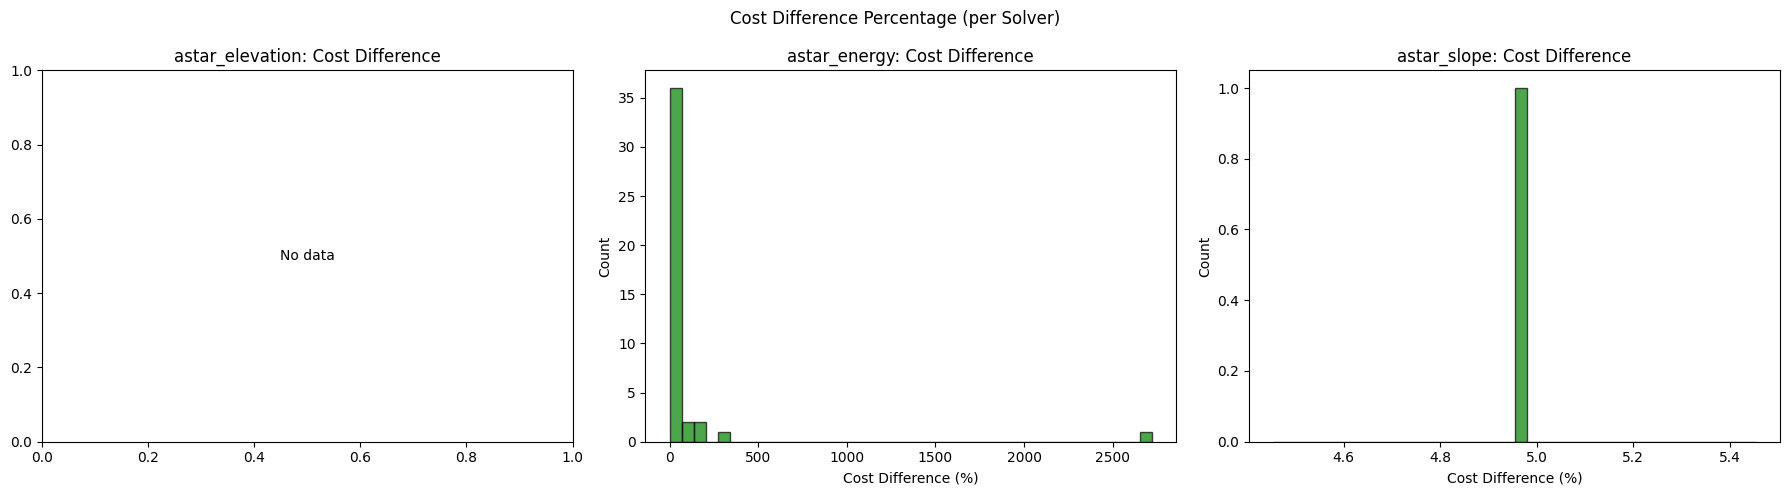

/tmp/ipykernel_405850/922287259.py:39: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([d for _, d in valid], labels=[s for s, _ in valid])


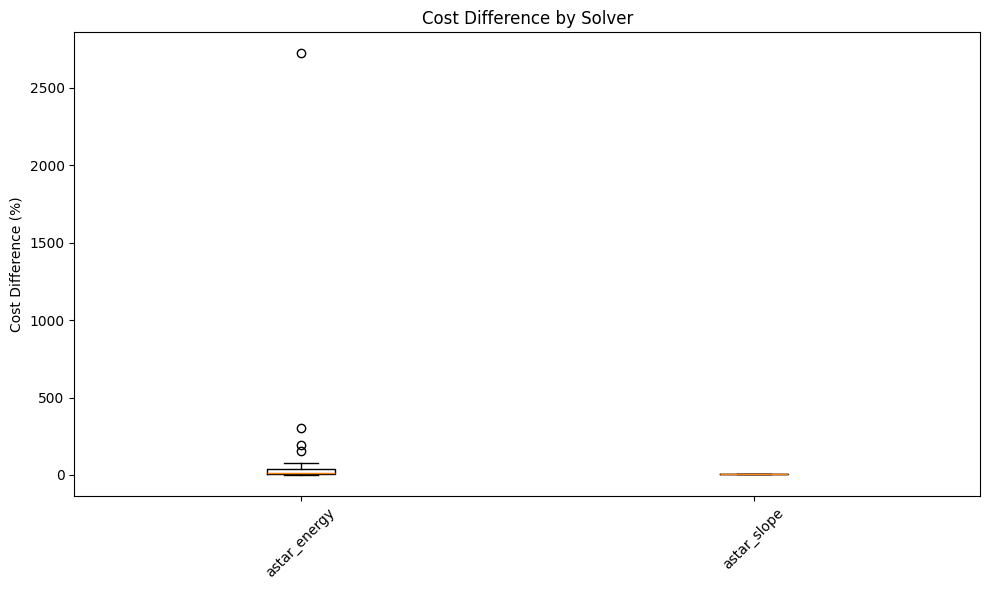

In [33]:
# Cost difference percentage per solver
n_solvers = len(SOLVER_NAMES)
if n_solvers == 0:
    print("No solvers configured.")
else:
    n_cols = min(3, n_solvers)
    n_rows = math.ceil(n_solvers / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
    if n_solvers == 1:
        axes = np.array([axes])
    axes = axes.flatten()

    for idx, solver_name in enumerate(SOLVER_NAMES):
        cd_vals = [v for v in solver_metrics[solver_name]["cost_diff_percents"] if v is not None and v > 0]
        if cd_vals:
            describe_stats(cd_vals, f"{solver_name} - Cost Difference %")
            axes[idx].hist(cd_vals, bins=40, edgecolor="black", alpha=0.7, color="green")
            axes[idx].set_xlabel("Cost Difference (%)")
            axes[idx].set_ylabel("Count")
            axes[idx].set_title(f"{solver_name}: Cost Difference")
        else:
            axes[idx].text(0.5, 0.5, "No data", ha="center", va="center", transform=axes[idx].transAxes)
            axes[idx].set_title(f"{solver_name}: Cost Difference")

    # Hide unused axes
    for idx in range(n_solvers, len(axes)):
        axes[idx].axis("off")

    plt.suptitle("Cost Difference Percentage (per Solver)")
    plt.tight_layout()
    plt.show()

    # Comparison box plot across solvers if multiple
    if n_solvers > 1:
        fig2, ax = plt.subplots(figsize=(10, 6))
        cd_data = [
            [v for v in solver_metrics[s]["cost_diff_percents"] if v is not None and v > 0] for s in SOLVER_NAMES
        ]
        valid = [(s, d) for s, d in zip(SOLVER_NAMES, cd_data) if d]
        if valid:
            ax.boxplot([d for _, d in valid], labels=[s for s, _ in valid])
            ax.set_ylabel("Cost Difference (%)")
            ax.set_title("Cost Difference by Solver")
            ax.tick_params(axis="x", rotation=45)
            plt.tight_layout()
            plt.show()

## 11b. Timing Summary

Plot per-sample timing distributions to identify hotspots:
- `tile_loading_seconds`
- `marker_search_seconds`
- `marker_find_path_without_seconds`
- `marker_find_path_with_seconds`

- `graph_prebuild_seconds`

- `obstacle_generation_seconds`- `image_write_seconds`

- `cost_compute_seconds`- `image_conversion_seconds`

- `tensor_save_seconds`- `metadata_write_seconds`

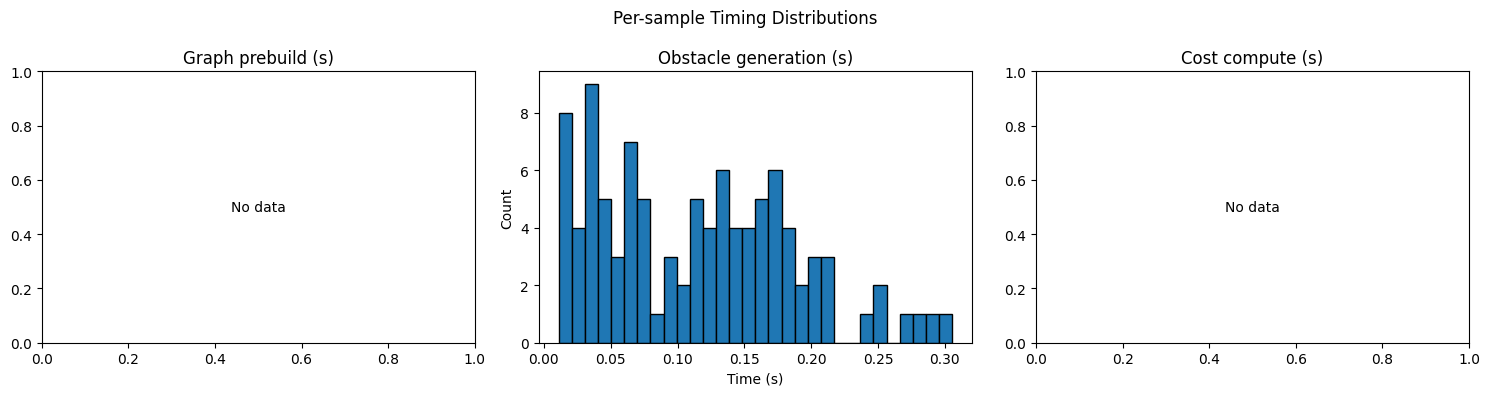

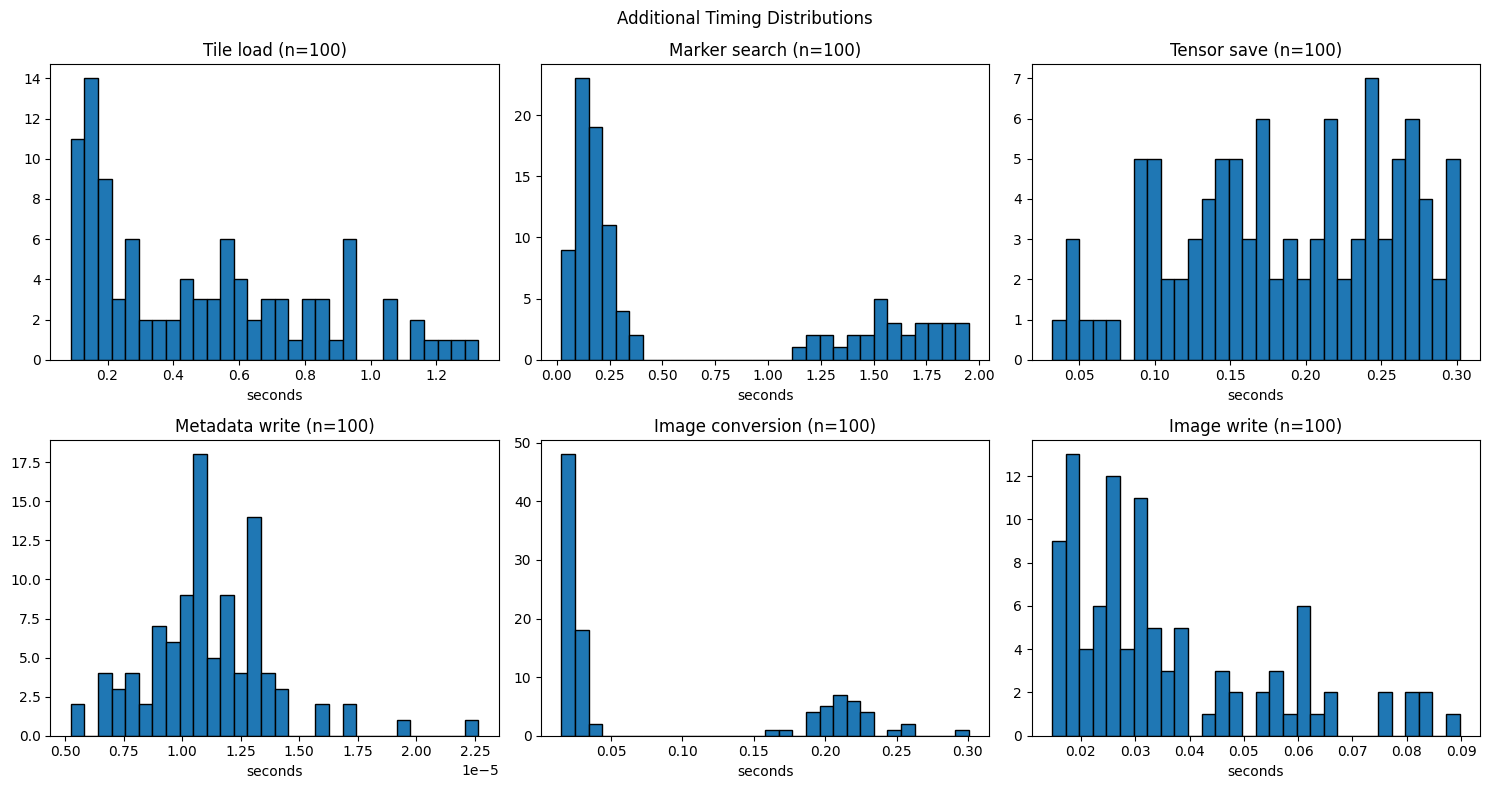

Obstacle generation seconds: count=100, mean=0.11, std=0.07, min=0.01, p25=0.05, median=0.11, p75=0.17, max=0.31
Tile loading seconds: count=100, mean=0.48, std=0.34, min=0.09, p25=0.17, median=0.42, p75=0.72, max=1.33
Marker search seconds: count=100, mean=0.62, std=0.68, min=0.02, p25=0.14, median=0.20, p75=1.40, max=1.95


In [34]:
# Timing distributions and stats
gp_vals = [v for v in graph_prebuild_seconds if v is not None and v >= 0]
og_vals = [v for v in obstacle_generation_seconds if v is not None and v >= 0]
cc_vals = [v for v in cost_compute_seconds if v is not None and v >= 0]
tl_vals = [v for v in tile_loading_seconds if v is not None and v >= 0]
ms_vals = [v for v in marker_search_seconds if v is not None and v >= 0]
ts_vals = [v for v in tensor_save_seconds if v is not None and v >= 0]
mw_vals = [v for v in metadata_write_seconds if v is not None and v >= 0]
ic_vals = [v for v in image_conversion_seconds if v is not None and v >= 0]
iw_vals = [v for v in image_write_seconds if v is not None and v >= 0]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

if gp_vals:
    axes[0].hist(gp_vals, bins=30, edgecolor="black")
    axes[0].set_title("Graph prebuild (s)")
    axes[0].set_xlabel("Time (s)")
    axes[0].set_ylabel("Count")
else:
    axes[0].text(0.5, 0.5, "No data", ha="center", va="center")
    axes[0].set_title("Graph prebuild (s)")

if og_vals:
    axes[1].hist(og_vals, bins=30, edgecolor="black")
    axes[1].set_title("Obstacle generation (s)")
    axes[1].set_xlabel("Time (s)")
    axes[1].set_ylabel("Count")
else:
    axes[1].text(0.5, 0.5, "No data", ha="center", va="center")
    axes[1].set_title("Obstacle generation (s)")

if cc_vals:
    axes[2].hist(cc_vals, bins=30, edgecolor="black")
    axes[2].set_title("Cost compute (s)")
    axes[2].set_xlabel("Time (s)")
    axes[2].set_ylabel("Count")
else:
    axes[2].text(0.5, 0.5, "No data", ha="center", va="center")
    axes[2].set_title("Cost compute (s)")

fig.suptitle("Per-sample Timing Distributions")
plt.tight_layout()
plt.show()

# Additional timing plots for available metrics
additional_metrics = [
    ("Tile load", tl_vals),
    ("Marker search", ms_vals),
    ("Tensor save", ts_vals),
    ("Metadata write", mw_vals),
    ("Image conversion", ic_vals),
    ("Image write", iw_vals),
]
additional_metrics = [(name, vals) for name, vals in additional_metrics if vals]
if additional_metrics:
    n2 = len(additional_metrics)
    cols2 = 3
    rows2 = math.ceil(n2 / cols2)
    fig2, axes2 = plt.subplots(rows2, cols2, figsize=(5 * cols2, 4 * rows2))
    ax_list2 = axes2.flatten() if hasattr(axes2, "flatten") else [axes2]
    for ax in ax_list2[n2:]:
        ax.axis("off")
    for ax, (name, vals) in zip(ax_list2, additional_metrics):
        ax.hist(vals, bins=30, edgecolor="black")
        ax.set_title(f"{name} (n={len(vals)})")
        ax.set_xlabel("seconds")
    fig2.suptitle("Additional Timing Distributions")
    plt.tight_layout()
    plt.show()

# Print summary stats for the timing buckets (if any exist)
if gp_vals:
    describe_stats(gp_vals, "Graph prebuild seconds")
if og_vals:
    describe_stats(og_vals, "Obstacle generation seconds")
if cc_vals:
    describe_stats(cc_vals, "Cost compute seconds")
if tl_vals:
    describe_stats(tl_vals, "Tile loading seconds")
if ms_vals:
    describe_stats(ms_vals, "Marker search seconds")

## 12. Identical Path Count (Per Solver)
Number of cases where the obstacle-aware path is exactly the same as the no-obstacle path, broken down by solver.

=== Identical Paths Analysis (per solver) ===

astar_elevation: 22 / 100 identical paths (22.0%)
astar_energy: 55 / 100 identical paths (55.0%)
astar_slope: 6 / 100 identical paths (6.0%)


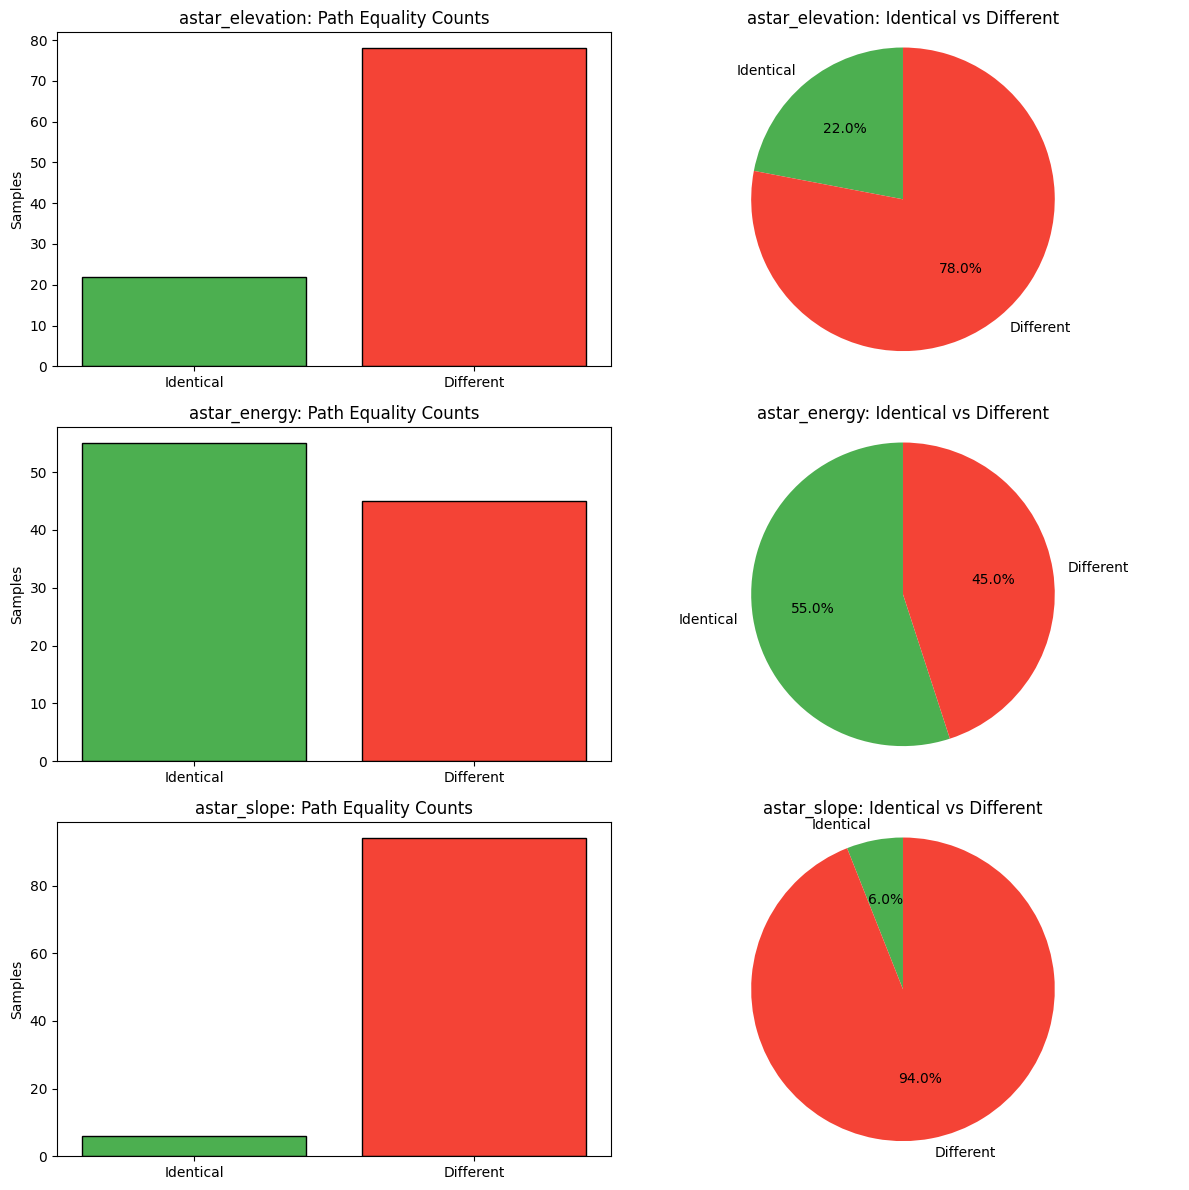


=== Overall (all solvers have identical free/obstacles paths): 6 / 100 ===


In [35]:
# Per-solver identical path statistics
print("=== Identical Paths Analysis (per solver) ===\n")

n_solvers = len(SOLVER_NAMES)
if n_solvers == 0:
    print("No solvers configured.")
else:
    # Create subplots: one row per solver with bar + pie
    fig, axes = plt.subplots(n_solvers, 2, figsize=(12, 4 * n_solvers))
    if n_solvers == 1:
        axes = axes.reshape(1, 2)

    for idx, solver_name in enumerate(SOLVER_NAMES):
        identical = solver_metrics[solver_name]["identical_paths_count"]
        if samples_processed > 0:
            pct_identical = (identical / samples_processed) * 100
        else:
            pct_identical = 0.0

        print(f"{solver_name}: {identical} / {samples_processed} identical paths ({pct_identical:.1f}%)")

        labels = ["Identical", "Different"]
        counts = [identical, max(samples_processed - identical, 0)]
        colors = ["#4caf50", "#f44336"]

        # Bar chart
        axes[idx, 0].bar(labels, counts, color=colors, edgecolor="black")
        axes[idx, 0].set_ylabel("Samples")
        axes[idx, 0].set_title(f"{solver_name}: Path Equality Counts")

        # Pie chart
        if samples_processed > 0:
            axes[idx, 1].pie(counts, labels=labels, colors=colors, autopct="%1.1f%%", startangle=90)
            axes[idx, 1].set_title(f"{solver_name}: Identical vs Different")
            axes[idx, 1].axis("equal")
        else:
            axes[idx, 1].axis("off")
            axes[idx, 1].text(0.5, 0.5, "No samples", ha="center", va="center")

    plt.tight_layout()
    plt.show()

# Overall: paths identical across ALL solvers
print(
    f"\n=== Overall (all solvers have identical free/obstacles paths): {identical_paths_count} / {samples_processed} ==="
)